# Solar forecast analysis

Data checks, individual-model performance, the blended DTU forecast, and a separate held-out test.

In [130]:
import matplotlib.pyplot as plt
from cycler import cycler

# Define a muted palette that complements the poster colors
palette = [
    "#807098",  # Dusty purple
    "#526F91",  # Muted blue
    "#B18A32",  # Muted gold
    "#527B67",  # Sage green
    "#B66F58",  # Terracotta
    "#9C6481",  # Dusty rose
    "#49858A",  # Muted teal
    "#817565",  # Warm taupe
]

# Set the default color cycle for newly created plots
plt.rcParams["axes.prop_cycle"] = cycler(color=palette)

# Keep each model's color consistent regardless of plotting order
colors = dict(zip([
    "dmi_harmonie_arome_europe",
    "metno_nordic",
    "ecmwf_ifs025",
    "ecmwf_aifs025_single",
    "gfs_global",
    "ecmwf_ifs",
    "dmi_seamless",
    "gfs_seamless",
], palette))

colors["blend"] = "#35313D"
# Readable plot defaults for notebook and poster exports.
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


In [131]:
import numpy as np
import matplotlib.pyplot as plt
import solarpy
import pvlib
import pandas as pd

In [132]:
from pathlib import Path
import sys
import importlib
import numpy as np
import pandas as pd

notebook_dir = Path.cwd()
sys.path.insert(0, str(notebook_dir))

import functions_new
importlib.reload(functions_new)

# New pandas versions no longer allow dropna=True inside stack().
def _interval_values_pandas_compatible(forecast, first_hour, last_hour):
    columns = [
        lead for lead in forecast.columns
        if first_hour <= lead <= last_hour
    ]
    if not columns:
        return pd.Series(dtype=float)

    subset = forecast.loc[:, columns].replace([np.inf, -np.inf], np.nan).copy()
    subset.index.name = "valid_time"
    subset.columns.name = "lead_time_h"
    values = subset.stack().dropna()
    values.index.names = ["valid_time", "lead_time_h"]
    return values

functions_new._interval_values = _interval_values_pandas_compatible

from functions_new import (
    get_dmi_ghi,
    resample_dmi_ghi_hourly,
    get_forecast_data,
    calculate_forecast_metrics,
    calculate_overall_metrics,
    our_blend_by_lead_time,
    our_blended_forecasts,
    fit_blend_weights_by_lead_time,
)

print("Using functions from:", Path(functions_new.__file__).resolve())


Using functions from: /Users/amandahietala/Documents/DTU/DTU-Code/Solar/Forecasting project/solar_forecast_project/notebooks/functions_new.py


## Data preparation and checks

In [133]:
#Get raw DMI measurements 
dmi_data = get_dmi_ghi(start="2025-11-09",end="2026-11-28", station="06019")

#Resample to hourly measurements
hourly_dmi = resample_dmi_ghi_hourly(dmi_data)

In [134]:
# Load the forecast files and match them with hourly measurements.
forecast_data = get_forecast_data(
    hourly_dmi,
    start="2026-11-09",
)


In [135]:
dmi_data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 55225 entries, 2025-11-09 00:00:00+00:00 to 2026-11-28 00:00:00+00:00
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ghi     55225 non-null  float64
dtypes: float64(1)
memory usage: 862.9 KB


## Filter night away using solpos

Find solar position, in order to filter night data points away

In [136]:
#Calculate solar position for forecast valid times
timestamps = pd.DatetimeIndex(pd.concat(forecast_data.values())["valid_time"].unique())

solpos = pvlib.solarposition.get_solarposition(
    timestamps,
    latitude=56.93,
    longitude=8.6412,
    method="nrel_numpy",
)

solar_elevation = solpos["apparent_elevation"]

#Only keeping the daylight hours
daylight_times = timestamps[solar_elevation.to_numpy() > 0]

df_forecast_day = {
    model: df[df["valid_time"].isin(daylight_times)].copy()
    for model, df in forecast_data.items()
}

It is easiest to work with one forecast model at a time. To avoid having the rows be specified by a multi-index, we can use ``.unstack()`` function for alle forecast models, such that the index becomes just the time and the lead time become the columns. And the resulting dataframes are stored in a dictionary for each model and can be plotted.

In [137]:
#Unstacking all forecast models
forecast_unstacked = {
    model: df.set_index(["valid_time", "lead_time_h"])["ghi_forecast"].unstack()
    for model, df in df_forecast_day.items()
}

### Forecast availability by model

Check the sample count and forecast horizon before comparing models.

In [138]:
for model, df in forecast_data.items():
    print(
        model,
        "| Forecasts:", len(df),
        "| Matched measurements:", df["ghi_measured"].notna().sum(),
        "| Max horizon:", df["lead_time_h"].max()
    )

dmi_harmonie_arome_europe | Forecasts: 23166 | Matched measurements: 22249 | Max horizon: 56.0
metno_nordic | Forecasts: 23709 | Matched measurements: 22721 | Max horizon: 57.0
ecmwf_ifs025 | Forecasts: 65250 | Matched measurements: 55050 | Max horizon: 167.0
ecmwf_aifs025_single | Forecasts: 65250 | Matched measurements: 55050 | Max horizon: 167.0
gfs_global | Forecasts: 65250 | Matched measurements: 55050 | Max horizon: 167.0
ecmwf_ifs | Forecasts: 65250 | Matched measurements: 55050 | Max horizon: 167.0
dmi_seamless | Forecasts: 65250 | Matched measurements: 55050 | Max horizon: 167.0
gfs_seamless | Forecasts: 65250 | Matched measurements: 55050 | Max horizon: 167.0


In [139]:
scores = calculate_forecast_metrics(
    forecast_unstacked,
    hourly_dmi,
)


In [140]:
# RMSE and bias are used as the forecast error metrics.


In [141]:
# Compact overall comparison using the same metrics as the assignment.
overall_scores = calculate_overall_metrics(scores)
overall_scores = overall_scores[["model", "rmse", "bias", "n"]].sort_values("rmse")
display(
    overall_scores.style
    .format({"rmse": "{:.1f}", "bias": "{:.1f}", "n": "{:.0f}"})
)


,model,rmse,bias,n
2,ecmwf_aifs025_single,36.1,0.4,17201
4,ecmwf_ifs025,38.6,-8.0,17201
3,ecmwf_ifs,39.6,-8.5,17201
7,metno_nordic,40.8,-1.2,7075
5,gfs_global,42.5,-3.7,17201
6,gfs_seamless,42.5,-3.7,17201
1,dmi_seamless,44.1,-9.5,17201
0,dmi_harmonie_arome_europe,47.1,-10.0,6969


In [142]:
max_evaluated_lead = (
    scores.loc[scores["n"] > 0]
    .groupby("model")["lead_time_h"]
    .max()
)

print(max_evaluated_lead)

model
dmi_harmonie_arome_europe     56.0
dmi_seamless                 159.0
ecmwf_aifs025_single         159.0
ecmwf_ifs                    159.0
ecmwf_ifs025                 159.0
gfs_global                   159.0
gfs_seamless                 159.0
metno_nordic                  57.0
Name: lead_time_h, dtype: float64


## Individual-model analysis

### Forecasted versus measured GHI at a 10-hour lead time

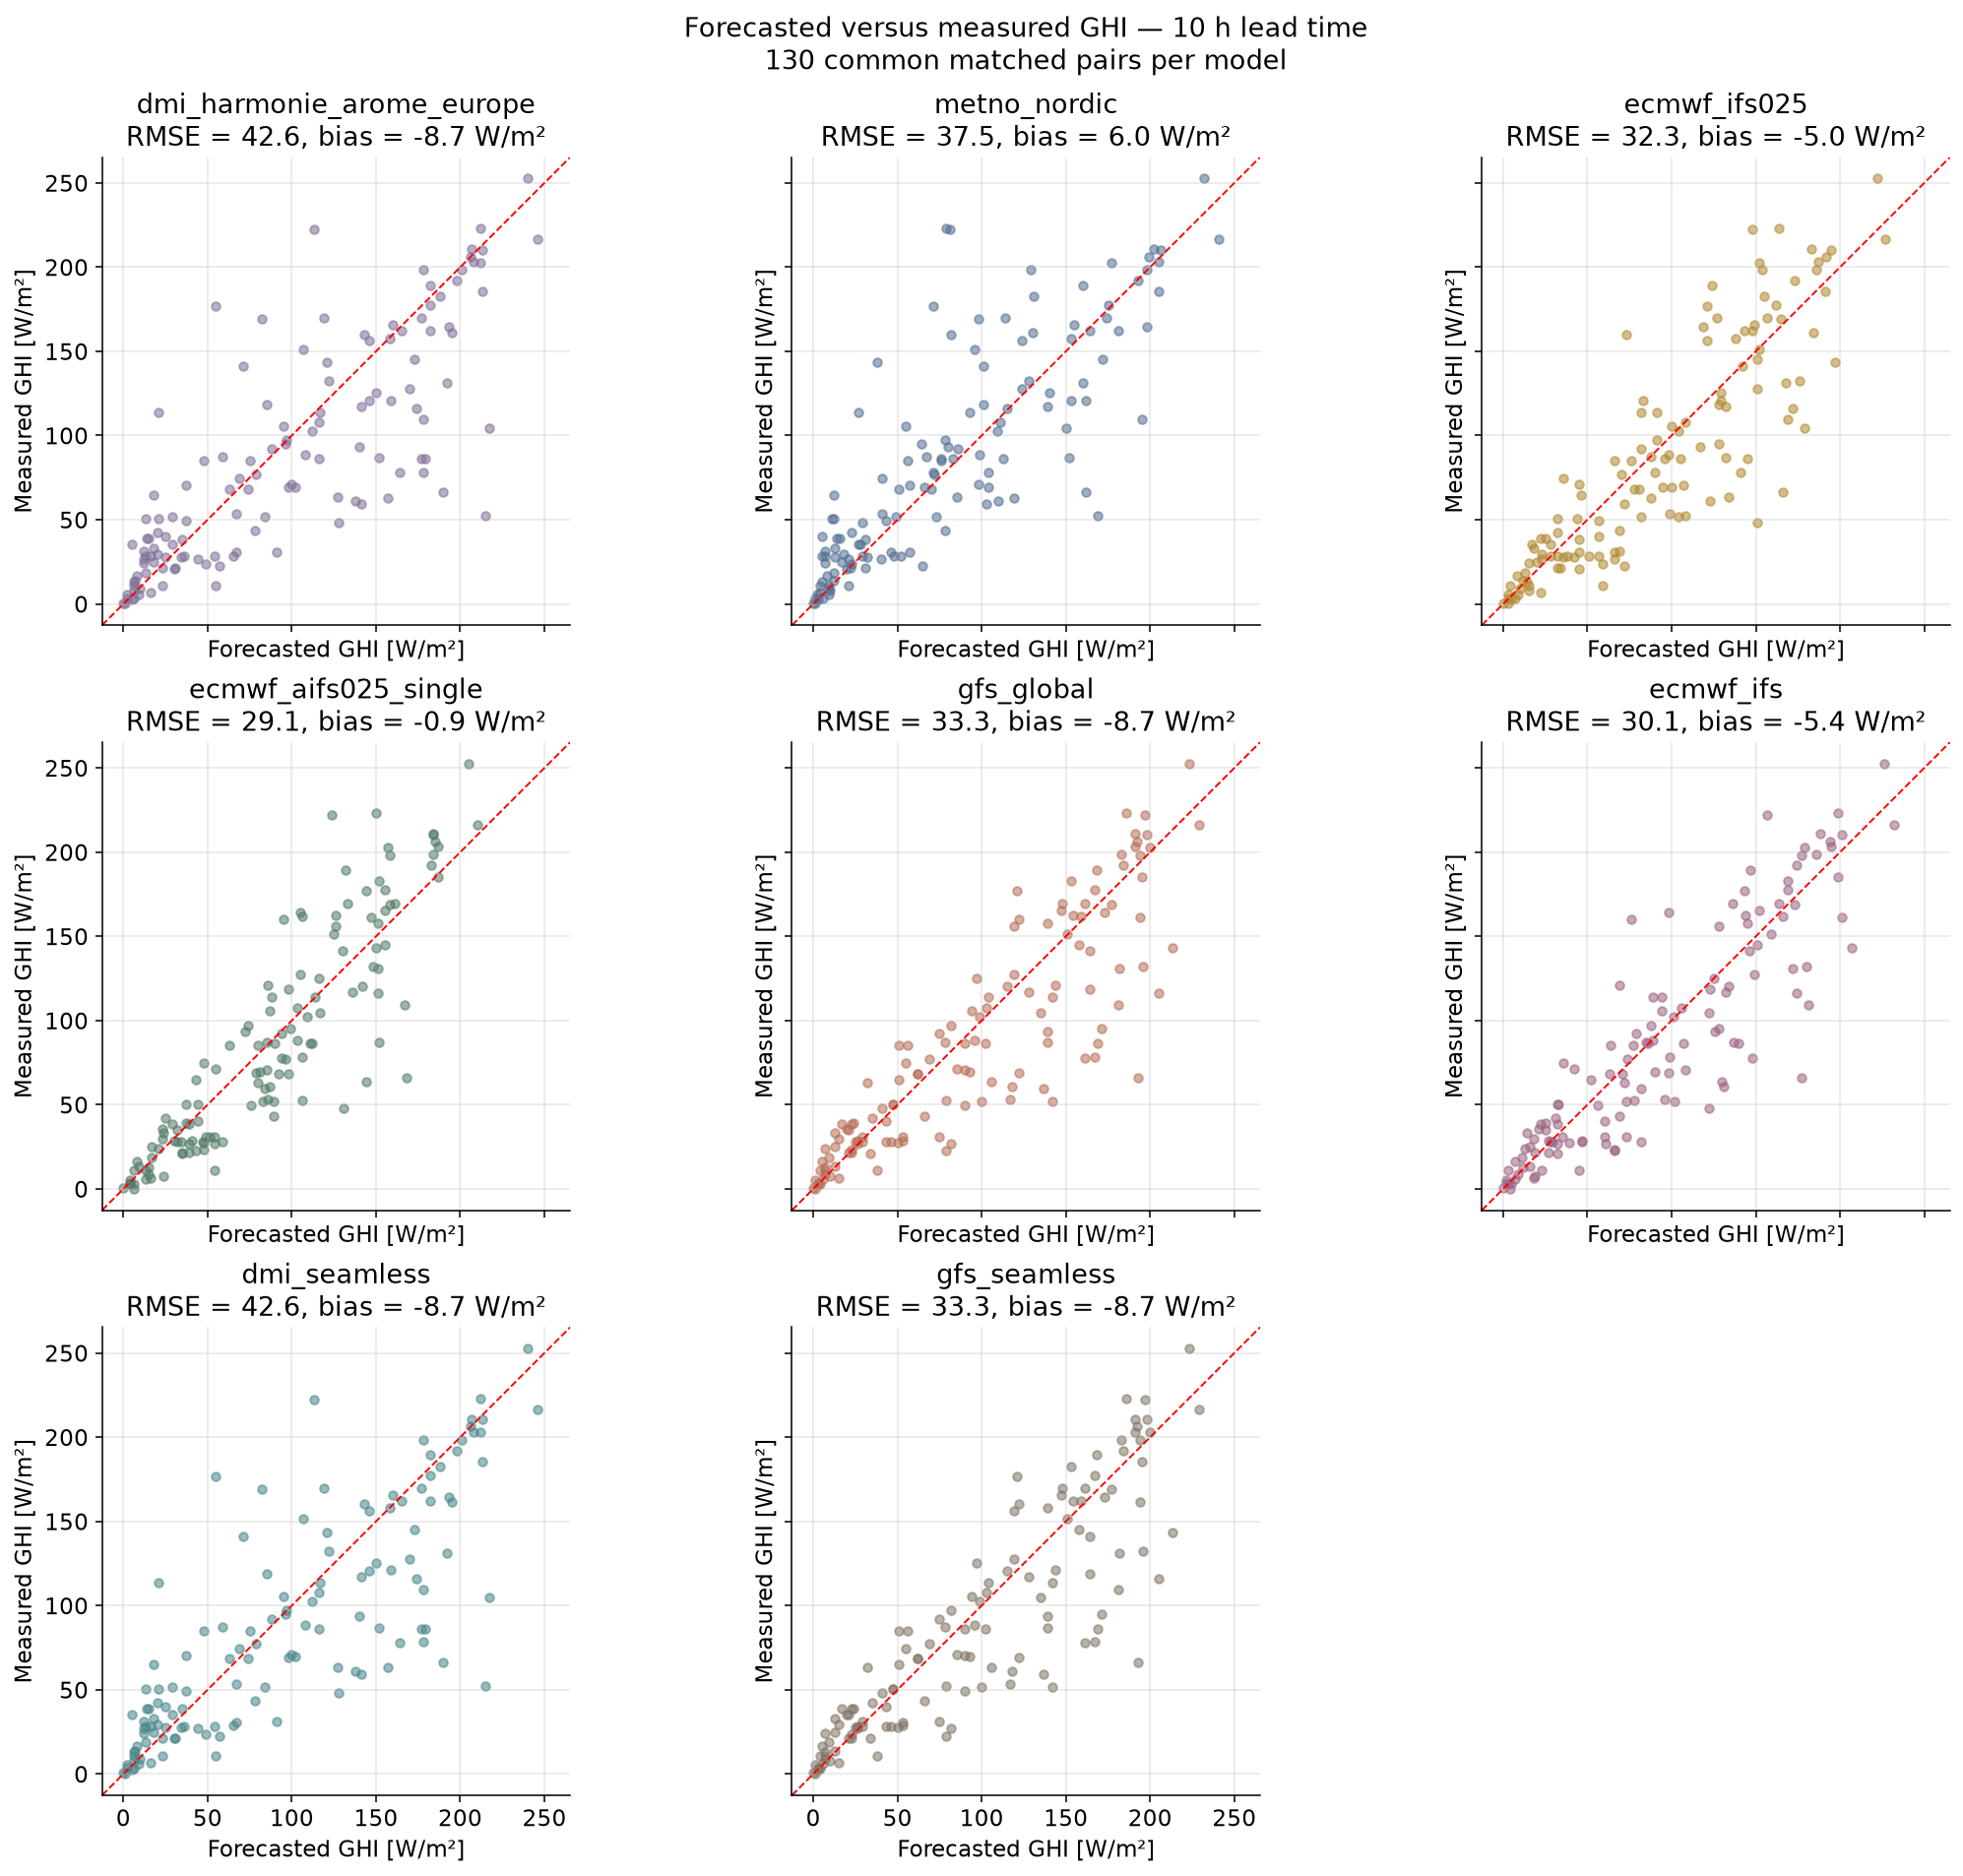

In [143]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

lead_time = 10
measured = hourly_dmi["ghi_measured"].replace([np.inf, -np.inf], np.nan)

predictions = {}
for model, forecast in forecast_unstacked.items():
    if lead_time in forecast.columns:
        predictions[model] = forecast[lead_time].replace(
            [np.inf, -np.inf], np.nan
        ).rename(model)

if not predictions:
    raise ValueError(f"No forecasts are available at lead time {lead_time} h.")

# Use the same valid times for every model in this figure.
comparison = pd.concat(predictions.values(), axis=1)
comparison = comparison.join(measured.rename("measured"))
comparison = comparison.replace([np.inf, -np.inf], np.nan).dropna()

if comparison.empty:
    raise ValueError(f"No common measured pairs at lead time {lead_time} h.")

all_values = comparison.to_numpy(dtype=float)
lower = min(0, np.nanmin(all_values))
upper = max(1, np.nanmax(all_values))
padding = (upper - lower) * 0.05
limits = (lower - padding, upper + padding)

model_names = list(predictions)
ncols = 3
nrows = int(np.ceil(len(model_names) / ncols))
fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(15, 4.5 * nrows),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)
axes = np.atleast_1d(axes).ravel()

for ax, model in zip(axes, model_names):
    forecast_values = comparison[model]
    observations = comparison["measured"]
    error = observations - forecast_values
    rmse = np.sqrt(np.mean(error**2))
    bias = error.mean()

    ax.scatter(
        forecast_values,
        observations,
        color=colors.get(model, "#526F91"),
        alpha=0.55,
        s=20,
    )
    ax.plot(limits, limits, color="red", linestyle="--", linewidth=1)
    ax.set(
        xlim=limits,
        ylim=limits,
        xlabel="Forecasted GHI [W/m²]",
        ylabel="Measured GHI [W/m²]",
        title=f"{model}\nRMSE = {rmse:.1f}, bias = {bias:.1f} W/m²",
    )
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.3)

for ax in axes[len(model_names):]:
    ax.set_visible(False)

fig.suptitle(
    f"Forecasted versus measured GHI — {lead_time} h lead time\n"
    f"{len(comparison)} common matched pairs per model",
    fontsize=14,
)
plt.show()


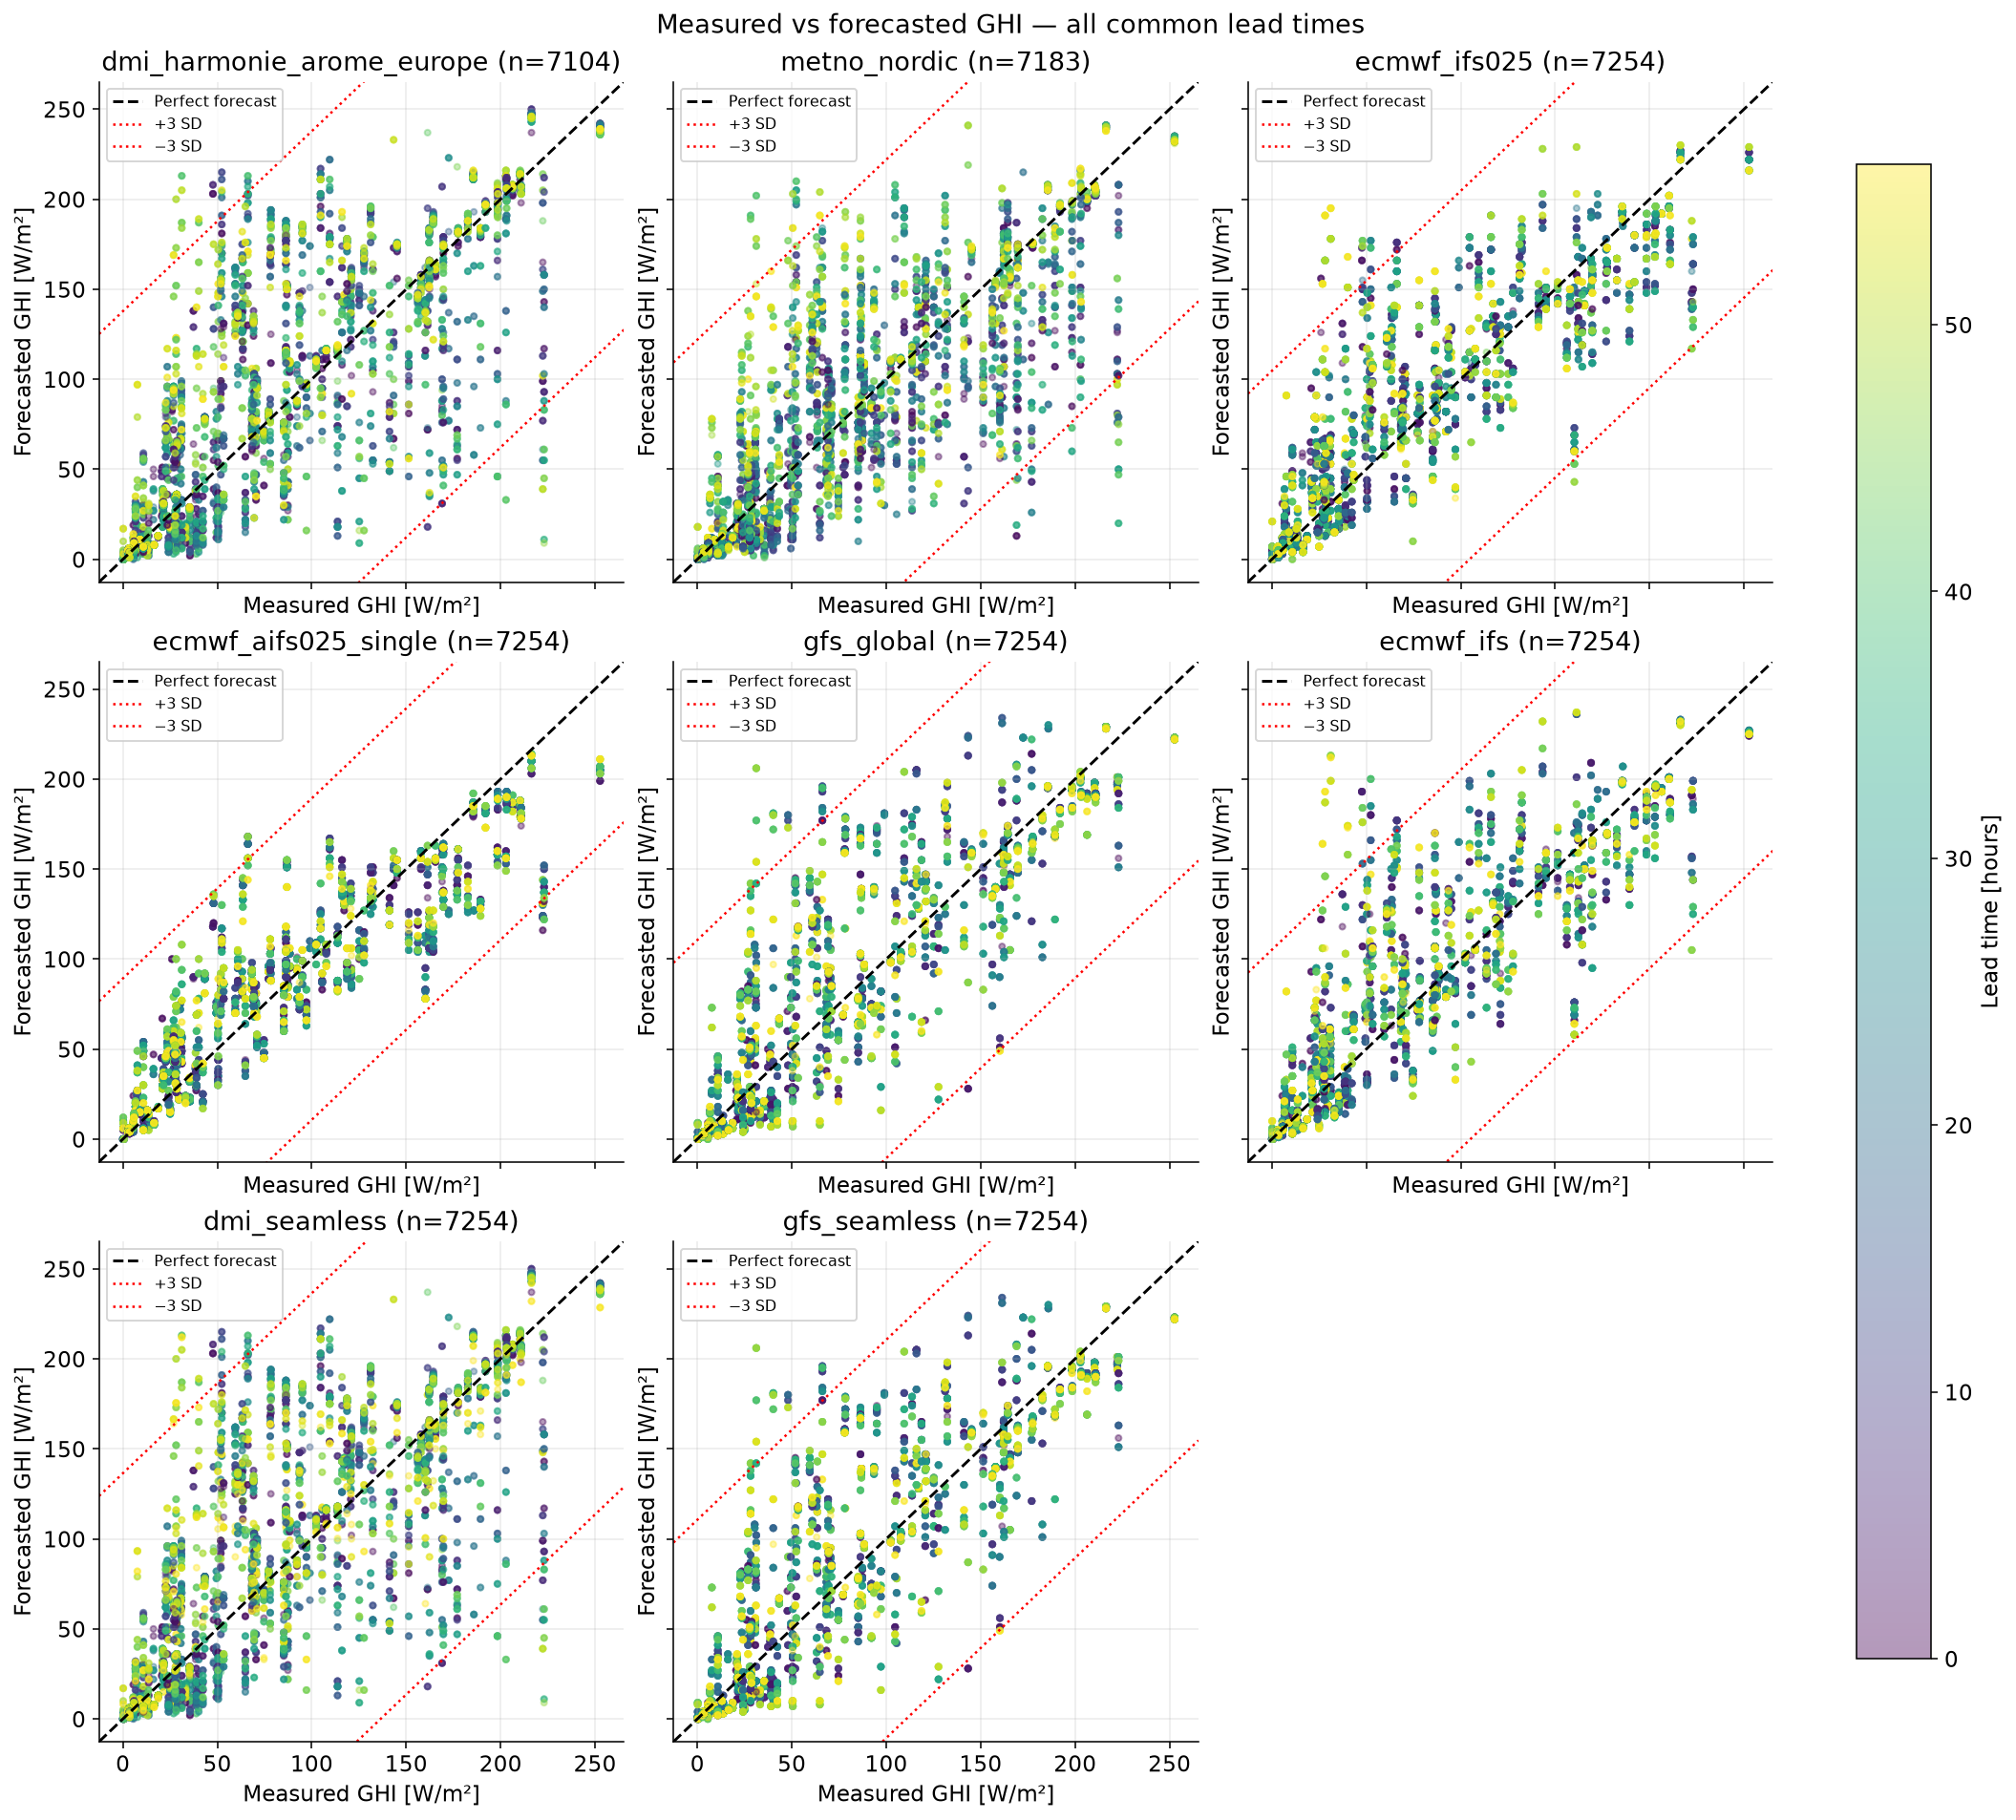

In [144]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

measured = (
    hourly_dmi["ghi_measured"]
    .replace([np.inf, -np.inf], np.nan)
)

# Find de numeriske lead times, som findes for hver model.
lead_columns_by_model = {}

for model, forecast in forecast_unstacked.items():
    lead_columns = {}
    for column in forecast.columns:
        try:
            lead_columns[float(column)] = column
        except (TypeError, ValueError):
            continue
    lead_columns_by_model[model] = lead_columns

# Brug fælles lead times, så modellerne sammenlignes på samme horisonter.
shared_leads = sorted(
    set.intersection(
        *(set(columns) for columns in lead_columns_by_model.values())
    )
)

if not shared_leads:
    raise ValueError("No common numeric lead times are available.")

plot_data = {}

for model, forecast in forecast_unstacked.items():
    selected_columns = [
        lead_columns_by_model[model][lead]
        for lead in shared_leads
    ]

    wide = forecast.loc[:, selected_columns].copy()
    wide.index.name = "valid_time"
    wide.columns = shared_leads
    wide.columns.name = "lead_time_h"

    long = wide.stack().rename("Forecasted").reset_index()
    long["Measured"] = measured.reindex(
        pd.DatetimeIndex(long["valid_time"])
    ).to_numpy()

    long = long.replace([np.inf, -np.inf], np.nan).dropna(
        subset=["Measured", "Forecasted"]
    )

    if not long.empty:
        plot_data[model] = long

if not plot_data:
    raise ValueError("No matching measured and forecasted data were found.")

# Fælles aksegrænser gør modellerne lettere at sammenligne.
all_values = np.concatenate([
    data[["Measured", "Forecasted"]].to_numpy().ravel()
    for data in plot_data.values()
])
axis_min = np.nanmin(all_values)
axis_max = np.nanmax(all_values)
padding = (axis_max - axis_min) * 0.05 if axis_max > axis_min else 1
axis_min -= padding
axis_max += padding

x_values = np.linspace(axis_min, axis_max, 200)

ncols = 3
nrows = math.ceil(len(plot_data) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5 * ncols, 4.5 * nrows),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)
axes = np.asarray(axes).reshape(-1)

scatter = None

for ax, (model, data) in zip(axes, plot_data.items()):
    scatter = ax.scatter(
        data["Measured"],
        data["Forecasted"],
        c=data["lead_time_h"],
        cmap="viridis",
        vmin=min(shared_leads),
        vmax=max(shared_leads),
        s=10,
        alpha=0.4,
    )

    # Perfekt prognose: forecasted GHI = measured GHI.
    ax.plot(
        x_values,
        x_values,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Perfect forecast",
    )

    # Beregn residualernes standardafvigelse for denne model.
    residuals = data["Forecasted"] - data["Measured"]
    three_std = 3 * residuals.std(ddof=1)

    # Linjer ved ±3 standardafvigelser fra den perfekte prognoselinje.
    ax.plot(
        x_values,
        x_values + three_std,
        color="red",
        linestyle=":",
        linewidth=1.3,
        label="+3 SD",
    )
    ax.plot(
        x_values,
        x_values - three_std,
        color="red",
        linestyle=":",
        linewidth=1.3,
        label="−3 SD",
    )

    ax.set_title(f"{model} (n={len(data)})")
    ax.set_xlim(axis_min, axis_max)
    ax.set_ylim(axis_min, axis_max)
    ax.set_xlabel("Measured GHI [W/m²]")
    ax.set_ylabel("Forecasted GHI [W/m²]")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="upper left")

for ax in axes[len(plot_data):]:
    ax.set_visible(False)

colorbar = fig.colorbar(scatter, ax=axes[:len(plot_data)], shrink=0.9)
colorbar.set_label("Lead time [hours]")

fig.suptitle(
    "Measured vs forecasted GHI — all common lead times",
    fontsize=14,
)
plt.show()

### RMSE and bias by lead time on training data

In [145]:
# Define the six-hour intervals used by the blended model.
blend_intervals = [(first, first + 5) for first in range(10, 106, 6)]

# Split chronologically by valid time so one measured hour cannot occur in
# both training and validation, even when it has forecasts at several leads.
measured_times = hourly_dmi.index[hourly_dmi["ghi_measured"].notna()]
forecast_times = pd.Index([])
for forecast in forecast_unstacked.values():
    forecast_times = forecast_times.union(forecast.index)

matched_times = measured_times.intersection(forecast_times).sort_values()
if len(matched_times) < 2:
    raise ValueError("Fewer than two matched valid times are available for the split.")

split_position = int(len(matched_times) * 0.70)
split_position = min(max(split_position, 1), len(matched_times) - 1)
validation_start = matched_times[split_position]

forecast_train = {
    model: forecast.loc[forecast.index < validation_start].copy()
    for model, forecast in forecast_unstacked.items()
}
forecast_validation = {
    model: forecast.loc[forecast.index >= validation_start].copy()
    for model, forecast in forecast_unstacked.items()
}

print(f"Training ends before: {validation_start}")
print(f"Validation starts:    {validation_start}")
print(f"Matched valid times:  {len(matched_times)}")


Training ends before: 2026-11-21 14:00:00+00:00
Validation starts:    2026-11-21 14:00:00+00:00
Matched valid times:  146


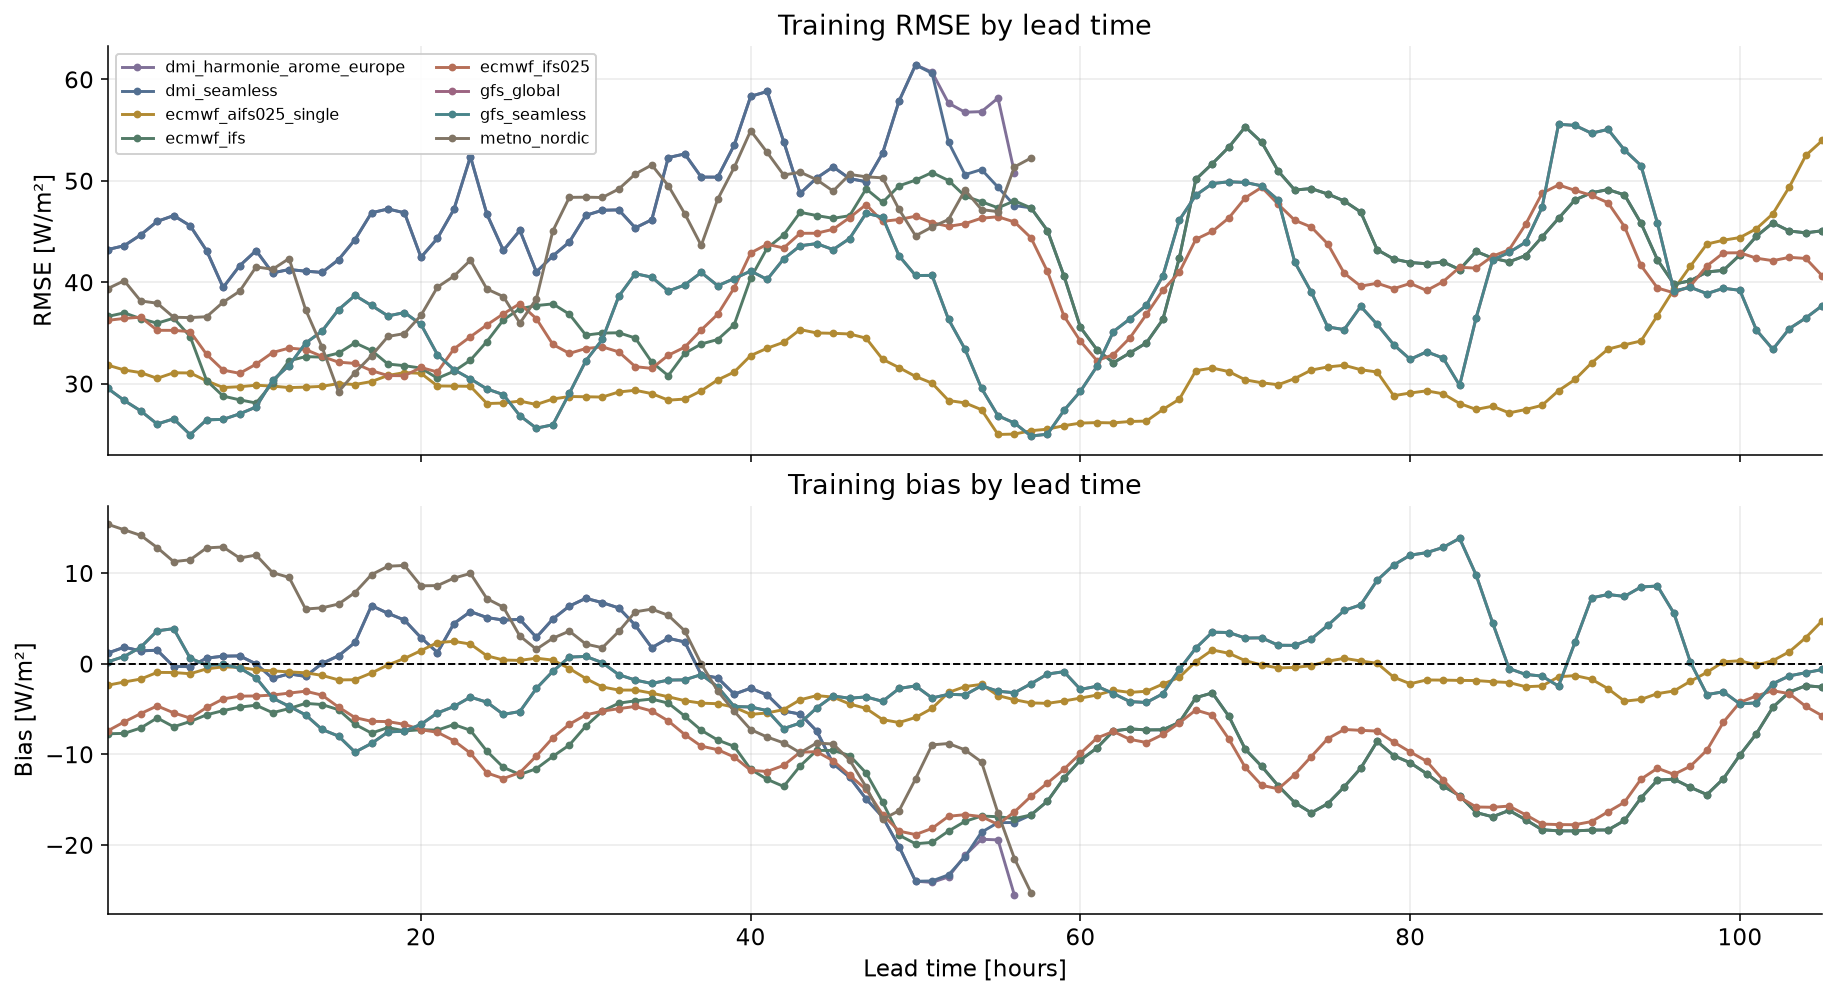

In [146]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

measured_train = (
    hourly_dmi["ghi_measured"]
    .replace([np.inf, -np.inf], np.nan)
)

training_scores = []

for model, forecast in forecast_train.items():
    for lead in forecast.columns:
        try:
            lead_h = int(lead)
        except (TypeError, ValueError):
            continue

        if not 1 <= lead_h <= 105:
            continue

        prediction = forecast[lead].replace([np.inf, -np.inf], np.nan)
        observation = measured_train.reindex(prediction.index)

        pairs = pd.concat(
            [observation.rename("measured"), prediction.rename("forecast")],
            axis=1,
        ).dropna()

        if pairs.empty:
            continue

        error = pairs["measured"] - pairs["forecast"]

        training_scores.append({
            "model": model,
            "lead_time_h": lead_h,
            "n": len(pairs),
            "rmse": np.sqrt(np.mean(error**2)),
            "bias": error.mean(),
        })

training_scores = pd.DataFrame(training_scores)

# Skjul lead times med få observationer.
min_samples = 10
training_scores.loc[
    training_scores["n"] < min_samples, ["rmse", "bias"]
] = np.nan

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 7),
    sharex=True,
    constrained_layout=True,
)

for model, group in training_scores.groupby("model"):
    group = group.sort_values("lead_time_h")

    axes[0].plot(
        group["lead_time_h"],
        group["rmse"],
        marker=".",
        label=model,
    )

    axes[1].plot(
        group["lead_time_h"],
        group["bias"],
        marker=".",
        label=model,
    )

# RMSE
axes[0].set_title("Training RMSE by lead time")
axes[0].set_ylabel("RMSE [W/m²]")
axes[0].grid(alpha=0.25)

axes[0].legend(
    loc="upper left",
    ncol=2,
    fontsize=8,
    frameon=True,
    framealpha=0.9,
)

# Bias
axes[1].axhline(
    0, color="black", linewidth=1, linestyle="--"
)

axes[1].set_title("Training bias by lead time")
axes[1].set_ylabel("Bias [W/m²]")
axes[1].set_xlabel("Lead time [hours]")
axes[1].grid(alpha=0.25)

# Consistent layout
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(1, 105)

# Save both plots as one figure
fig.savefig(
    "Training_RMSE_Bias.svg",
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    "Training_RMSE_Bias.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

### Measured GHI and all model forecasts at a 6-hour lead time

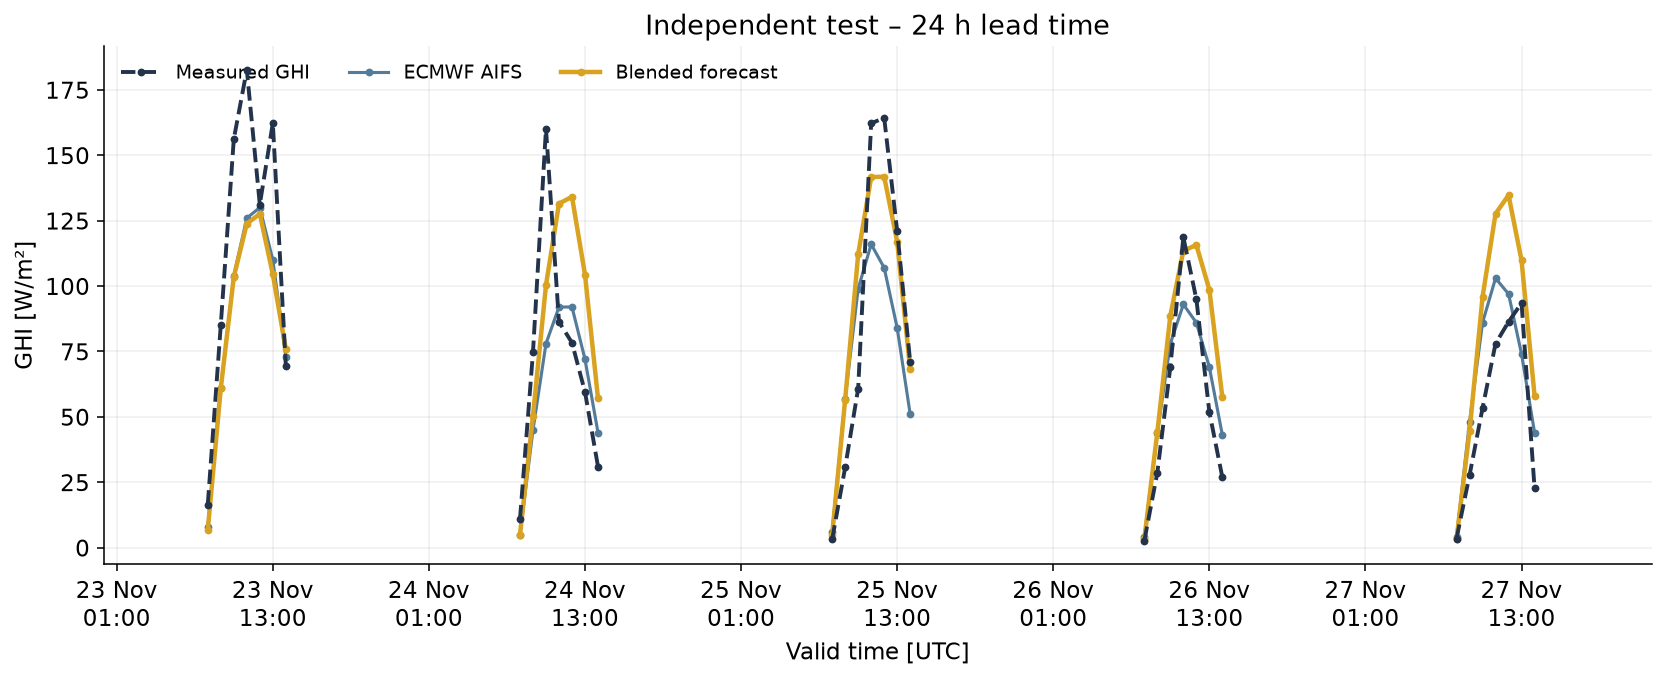

In [147]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Select forecast horizon and baseline model
plot_lead = 24
baseline_model = "ecmwf_aifs025_single"

measured = hourly_dmi["ghi_measured"].replace(
    [np.inf, -np.inf], np.nan
)

# Extract forecasts from independent test data
baseline = backtest_test[baseline_model].copy()
blend = backtest_blend.copy()

baseline.columns = baseline.columns.astype(float).round().astype(int)
blend.columns = blend.columns.astype(float).round().astype(int)

# Match measured and forecasted GHI
plot_data = pd.concat(
    [
        measured.rename("Measured GHI"),
        baseline[plot_lead].rename("ECMWF AIFS"),
        blend[plot_lead].rename("Blended forecast"),
    ],
    axis=1,
).replace([np.inf, -np.inf], np.nan).dropna()

# Insert missing hours to avoid connecting lines overnight
plot_index = pd.date_range(
    start=plot_data.index.min().floor("D"),
    end=plot_data.index.max().floor("D") + pd.Timedelta(days=1),
    freq="h",
    inclusive="left",
)

plot_data = plot_data.reindex(plot_index)

# Plot
fig, ax = plt.subplots(figsize=(12.15, 5))

ax.plot(
    plot_data.index,
    plot_data["Measured GHI"],
    color="#23334B",
    linestyle="--",
    linewidth=2,
    marker=".",
    label="Measured GHI",
    zorder=10,
)

ax.plot(
    plot_data.index,
    plot_data["ECMWF AIFS"],
    color="#537B9A",
    linewidth=1.6,
    marker=".",
    label="ECMWF AIFS",
)

ax.plot(
    plot_data.index,
    plot_data["Blended forecast"],
    color="#D9A321",
    linewidth=2.3,
    marker=".",
    label="Blended forecast",
    zorder=9,
)

# Formatting
ax.set_title(
    f"Independent test – {plot_lead} h lead time",
    fontsize=14,
)

ax.set_ylabel("GHI [W/m²]", fontsize=12)
ax.set_xlabel("Valid time [UTC]", fontsize=12)

ax.xaxis.set_major_locator(mdates.HourLocator(interval=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d Nov\n%H:%M"))

ax.set_xlim(plot_index.min(), plot_index.max())
ax.grid(alpha=0.2)

ax.legend(
    loc="upper left",
    ncol=3,
    fontsize=10,
    frameon=False,
)

ax.spines[["top", "right"]].set_visible(False)

fig.subplots_adjust(
    left=0.075,
    right=0.985,
    bottom=0.16,
    top=0.90,
)

# Save figure for poster
fig.savefig("Measured_vs_AIFS_vs_Blend.svg", facecolor="white",)


plt.show()

### Daily clearness profiles

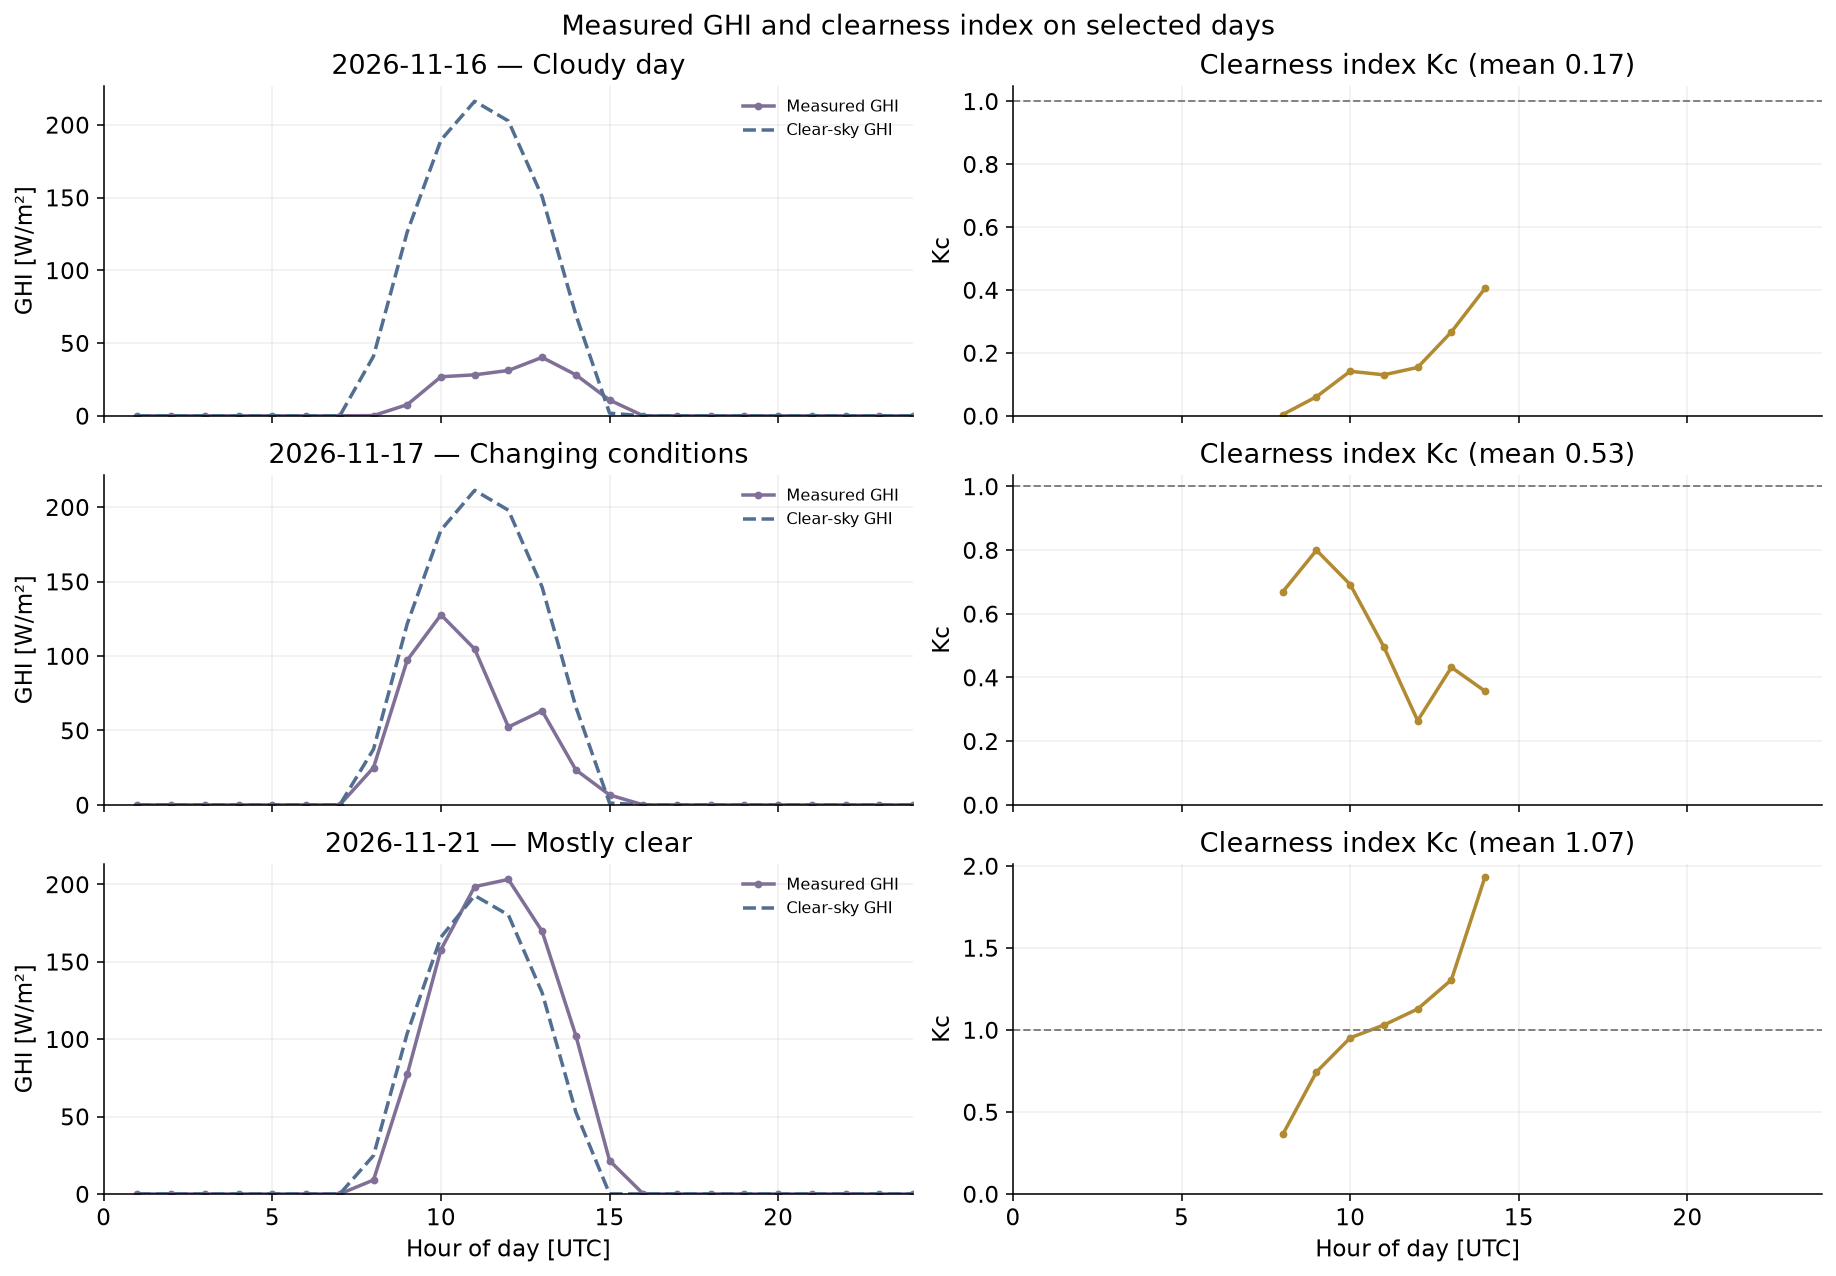

In [148]:
import numpy as np
import matplotlib.pyplot as plt

profile_days = {
    "2026-11-16": "Cloudy day",
    "2026-11-17": "Changing conditions",
    "2026-11-21": "Mostly clear",
}
solar_site = pvlib.location.Location(
    latitude=56.93,
    longitude=8.6412,
    tz="UTC",
    name="DMI station 06019",
)

fig, axes = plt.subplots(
    len(profile_days), 2,
    figsize=(13, 9),
    sharex=True,
    constrained_layout=True,
)

for row, (date, description) in enumerate(profile_days.items()):
    start = pd.Timestamp(date, tz="UTC")
    end = start + pd.Timedelta(days=1)
    daily_ghi = hourly_dmi.loc[
        (hourly_dmi.index > start) & (hourly_dmi.index <= end),
        "ghi_measured",
    ].replace([np.inf, -np.inf], np.nan).dropna()
    clear_sky_ghi = solar_site.get_clearsky(
        daily_ghi.index, model="ineichen"
    )["ghi"]
    daytime = clear_sky_ghi > 20
    clearness_index = (
        daily_ghi.loc[daytime] / clear_sky_ghi.loc[daytime]
    ).replace([np.inf, -np.inf], np.nan).dropna()

    hour = (daily_ghi.index - start).total_seconds() / 3600
    clear_sky_hour = (clear_sky_ghi.index - start).total_seconds() / 3600
    kc_hour = (clearness_index.index - start).total_seconds() / 3600
    ax_ghi, ax_kc = axes[row]
    ax_ghi.plot(hour, daily_ghi, marker="o", markersize=3, linewidth=1.8, label="Measured GHI")
    ax_ghi.plot(clear_sky_hour, clear_sky_ghi, linestyle="--", linewidth=1.8, label="Clear-sky GHI")
    ax_ghi.set_title(f"{date} — {description}")
    ax_ghi.set_ylabel("GHI [W/m²]")
    ax_ghi.set_ylim(bottom=0)
    ax_ghi.grid(alpha=0.2)
    ax_ghi.legend(frameon=False, fontsize=8)

    ax_kc.plot(kc_hour, clearness_index, marker="o", markersize=3, linewidth=1.8, color="#B18A32")
    ax_kc.axhline(1, color="grey", linestyle="--", linewidth=1)
    ax_kc.set_title(f"Clearness index Kc (mean {clearness_index.mean():.2f})")
    ax_kc.set_ylabel("Kc")
    ax_kc.set_ylim(bottom=0)
    ax_kc.grid(alpha=0.2)

for ax in axes[-1]:
    ax.set_xlabel("Hour of day [UTC]")
    ax.set_xlim(0, 24)
fig.suptitle("Measured GHI and clearness index on selected days", fontsize=14)
plt.show()


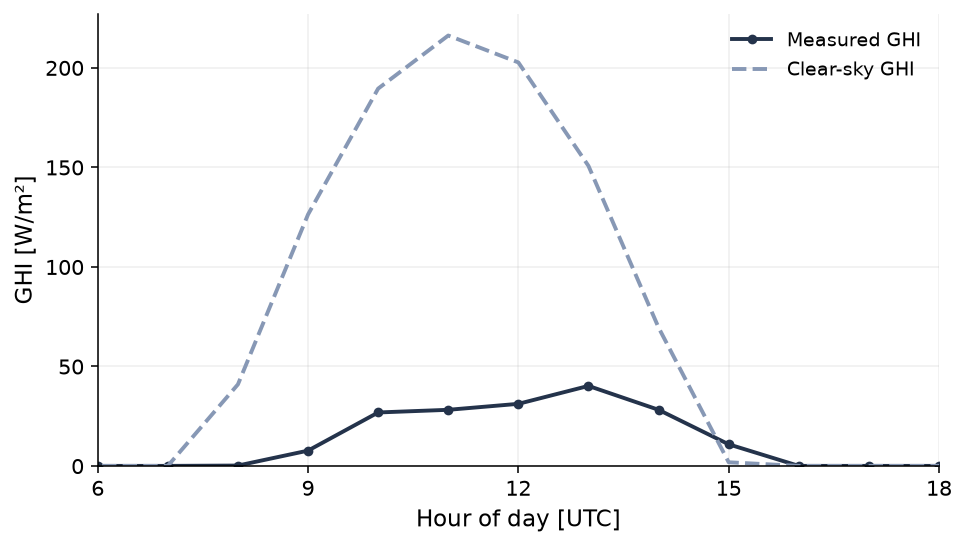

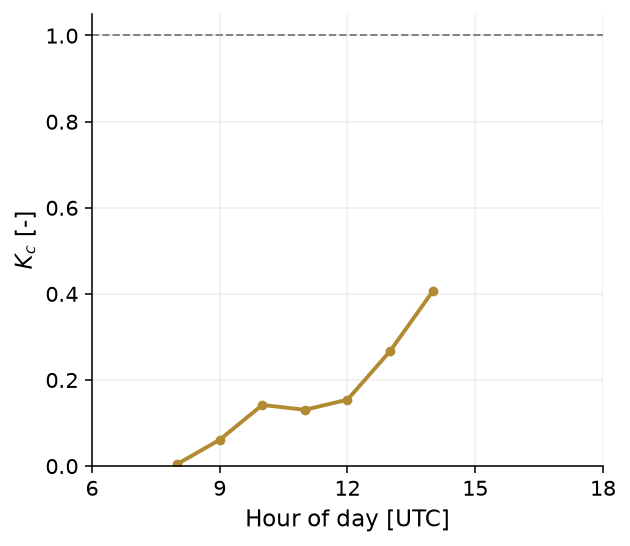

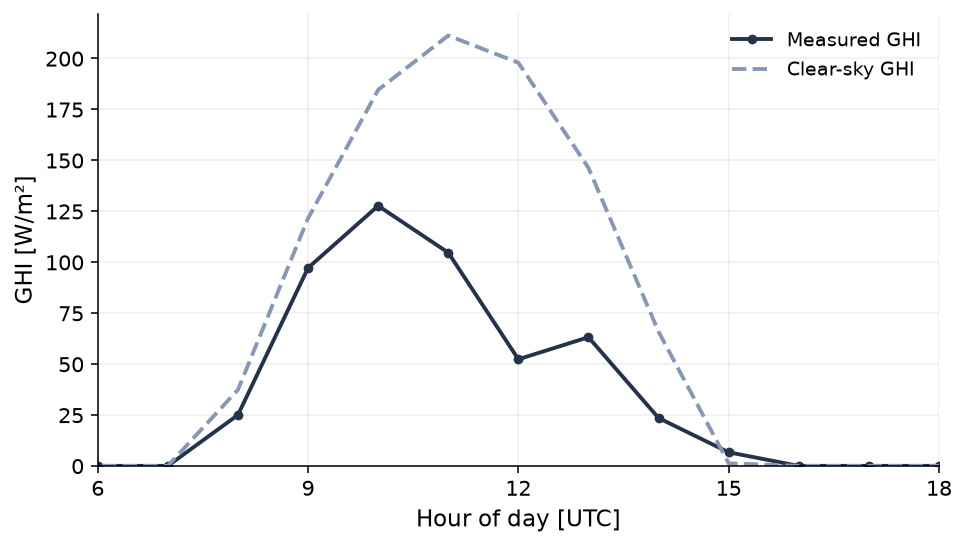

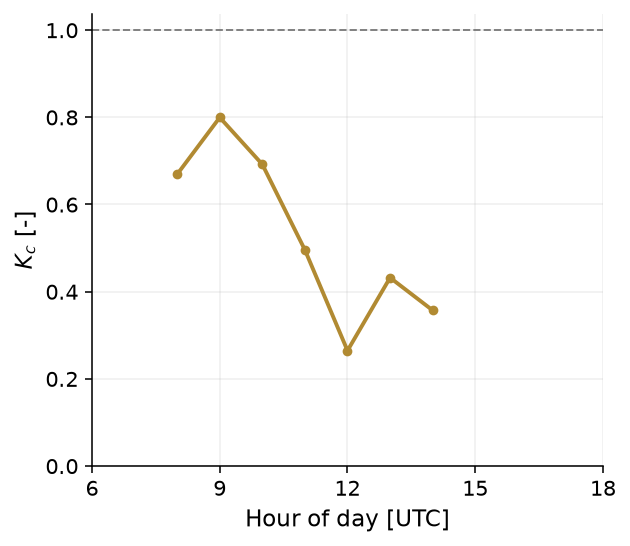

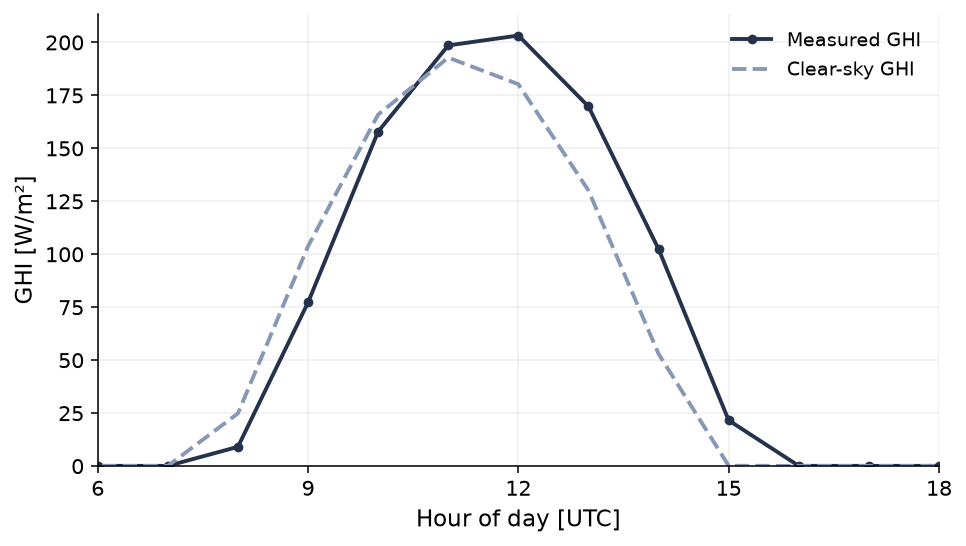

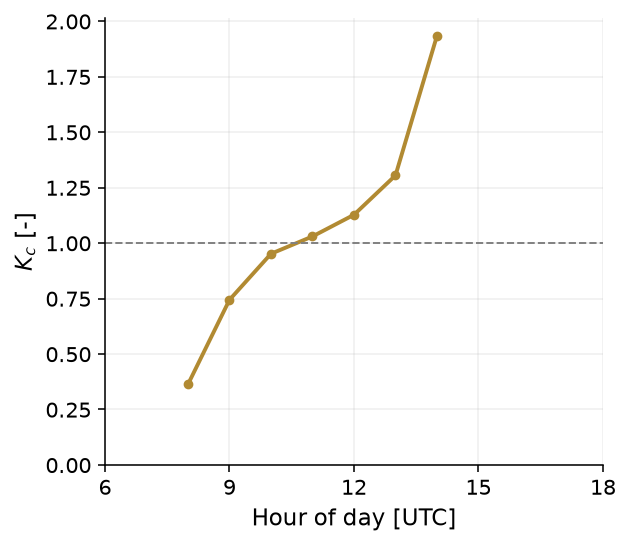

In [149]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

profile_days = {
    "2026-11-16": "Overcast",
    "2026-11-17": "Broken clouds",
    "2026-11-21": "Mostly clear",
}

solar_site = pvlib.location.Location(
    latitude=56.93,
    longitude=8.6412,
    tz="UTC",
    name="DMI station 06019",
)

for date, description in profile_days.items():

    start = pd.Timestamp(date, tz="UTC")
    end = start + pd.Timedelta(days=1)

    daily_ghi = hourly_dmi.loc[
        (hourly_dmi.index > start) & (hourly_dmi.index <= end),
        "ghi_measured",
    ].replace([np.inf, -np.inf], np.nan).dropna()

    clear_sky_ghi = solar_site.get_clearsky(
        daily_ghi.index, model="ineichen"
    )["ghi"]

    daytime = clear_sky_ghi > 20

    clearness_index = (
        daily_ghi.loc[daytime] / clear_sky_ghi.loc[daytime]
    ).replace([np.inf, -np.inf], np.nan).dropna()

    hour = (daily_ghi.index - start).total_seconds() / 3600
    clear_sky_hour = (clear_sky_ghi.index - start).total_seconds() / 3600
    kc_hour = (clearness_index.index - start).total_seconds() / 3600

    # 1. GHI profile
    fig, ax = plt.subplots(figsize=(7, 4))

    ax.plot(
        hour, daily_ghi,
        marker="o",
        markersize=4,
        linewidth=2,
        color="#24334B",
        label="Measured GHI",
    )

    ax.plot(
        clear_sky_hour, clear_sky_ghi,
        linestyle="--",
        linewidth=2,
        color="#8798B5",
        label="Clear-sky GHI",
    )

    ax.set_xlabel("Hour of day [UTC]", fontsize=12)
    ax.set_ylabel("GHI [W/m²]", fontsize=12)
    ax.set_xlim(6, 18)
    ax.set_xticks([6, 9, 12, 15, 18])
    ax.set_ylim(bottom=0)
    ax.tick_params(axis="both", labelsize=11)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=10)

    fig.tight_layout()
    fig.savefig(f"GHI_{date}.svg", facecolor="white")
    plt.show()


    # 2. Clear-sky index
    fig, ax = plt.subplots(figsize=(4.6, 4))

    ax.plot(
        kc_hour, clearness_index,
        marker="o",
        markersize=4,
        linewidth=2,
        color="#B18A32",
    )

    ax.axhline(
        1,
        color="grey",
        linestyle="--",
        linewidth=1,
    )

    ax.set_xlabel("Hour of day [UTC]", fontsize=12)
    ax.set_ylabel(r"$K_c$ [-]", fontsize=12)
    ax.set_xlim(6, 18)
    ax.set_xticks([6, 9, 12, 15, 18])
    ax.set_ylim(bottom=0)
    ax.tick_params(axis="both", labelsize=11)
    ax.grid(alpha=0.2)

    fig.tight_layout()
    fig.savefig(f"Kc_{date}.svg", facecolor="white")
    plt.show()

### Model performance by selected sky condition

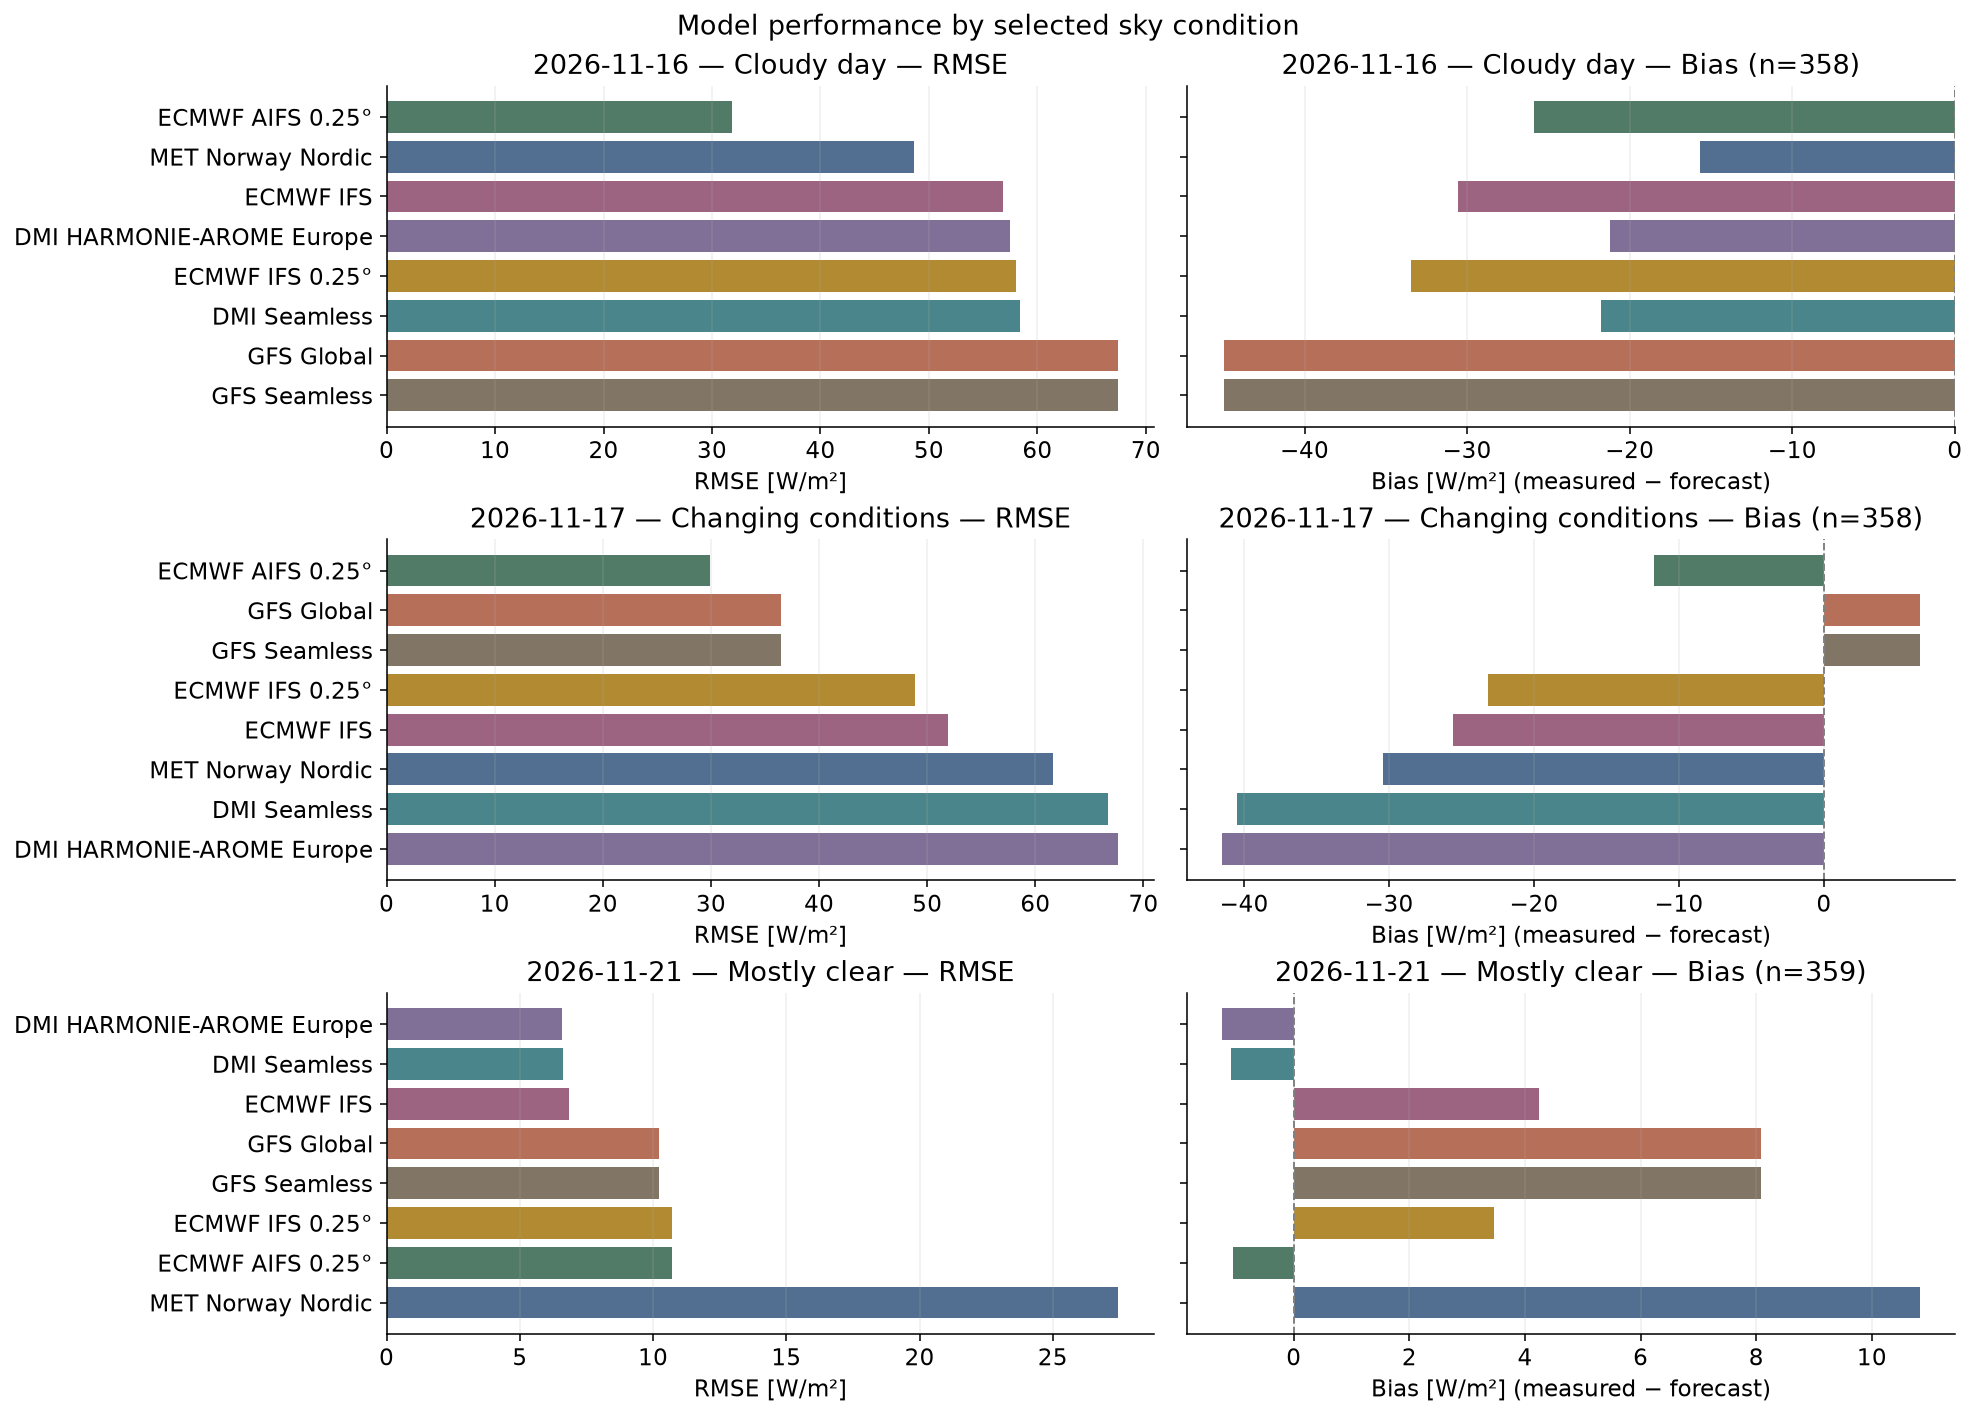

In [150]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

profile_days = {
    "2026-11-16": "Cloudy day",
    "2026-11-17": "Changing conditions",
    "2026-11-21": "Mostly clear",
}

models = list(forecast_unstacked)
measured = hourly_dmi["ghi_measured"].replace([np.inf, -np.inf], np.nan)

# Gør modelnavnene mere læsevenlige i figuren.
model_labels = {
    "dmi_harmonie_arome_europe": "DMI HARMONIE-AROME Europe",
    "metno_nordic": "MET Norway Nordic",
    "ecmwf_ifs025": "ECMWF IFS 0.25°",
    "ecmwf_aifs025_single": "ECMWF AIFS 0.25°",
    "gfs_global": "GFS Global",
    "ecmwf_ifs": "ECMWF IFS",
    "dmi_seamless": "DMI Seamless",
    "gfs_seamless": "GFS Seamless",
}

# Brug lokale farver, så cellen ikke afhænger af en tidligere definition af `colors`.
palette = [
    "#807098", "#526F91", "#B18A32", "#527B67",
    "#B66F58", "#9C6481", "#49858A", "#817565",
]
plot_colors = {
    model: palette[i % len(palette)]
    for i, model in enumerate(models)
}

# Sammenlign modellerne på de samme lead times.
shared_leads = set.intersection(
    *(set(forecast.columns) for forecast in forecast_unstacked.values())
)
shared_leads = sorted(lead for lead in shared_leads if 10 <= lead <= 54)

if not shared_leads:
    raise ValueError(
        "No common forecast lead times are available for the selected models."
    )

rmse_by_day = {}
bias_by_day = {}
common_counts = {}

for date, description in profile_days.items():
    start = pd.Timestamp(date, tz="UTC")
    end = start + pd.Timedelta(days=1)
    predictions = {}

    for model, forecast in forecast_unstacked.items():
        day_mask = (forecast.index > start) & (forecast.index <= end)
        subset = (
            forecast.loc[day_mask, shared_leads]
            .replace([np.inf, -np.inf], np.nan)
            .copy()
        )
        subset.index.name = "valid_time"
        subset.columns.name = "lead_time_h"
        predictions[model] = subset.stack().dropna()

    paired = pd.concat(predictions, axis=1).dropna()

    observations = measured.reindex(
        paired.index.get_level_values("valid_time")
    )
    observations.index = paired.index

    valid = observations.notna()
    paired = paired.loc[valid]
    observations = observations.loc[valid]

    errors = paired.rsub(observations, axis=0)

    label = f"{date} — {description}"
    rmse_by_day[label] = np.sqrt(errors.pow(2).mean())
    bias_by_day[label] = errors.mean()
    common_counts[label] = len(errors)

rmse_day_table = pd.DataFrame(rmse_by_day).T.reindex(columns=models)
bias_day_table = pd.DataFrame(bias_by_day).T.reindex(columns=models)

fig, axes = plt.subplots(
    len(profile_days),
    2,
    figsize=(14, 10),
    sharey="row",
    constrained_layout=True,
)

for row, label in enumerate(rmse_day_table.index):
    order = rmse_day_table.loc[label].sort_values().index
    display_labels = [
        model_labels.get(model, model) for model in order
    ]
    bar_colors = [
        plot_colors.get(model, "#526F91") for model in order
    ]

    axes[row, 0].barh(
        display_labels,
        rmse_day_table.loc[label, order],
        color=bar_colors,
    )
    axes[row, 0].invert_yaxis()
    axes[row, 0].set_title(f"{label} — RMSE")
    axes[row, 0].set_xlabel("RMSE [W/m²]")
    axes[row, 0].grid(axis="x", alpha=0.2)

    axes[row, 1].barh(
        display_labels,
        bias_day_table.loc[label, order],
        color=bar_colors,
    )
    axes[row, 1].axvline(0, color="grey", linestyle="--", linewidth=1)
    axes[row, 1].set_title(
        f"{label} — Bias (n={common_counts[label]})"
    )
    axes[row, 1].set_xlabel("Bias [W/m²] (measured − forecast)")
    axes[row, 1].grid(axis="x", alpha=0.2)

fig.suptitle("Model performance by selected sky condition", fontsize=14)
plt.show()

## Blended forecast and DTU submission

In [151]:
# Optimize weights on training data and keep the blend only when it improves
# validation RMSE over the training-selected single-model fallback.
weight_schedule, blend_diagnostics, weight_search = (
    fit_blend_weights_by_lead_time(
        forecast_train,
        forecast_validation,
        hourly_dmi,
        intervals=blend_intervals,
        min_train_samples=30,
        min_validation_samples=10,
    )
)

# This schedule contains the validated blend or a single-model fallback.
display(blend_diagnostics[[
    "interval",
    "status",
    "training_selected_single_model",
    "validation_rmse_best_single",
    "validation_rmse_blend",
    "n_validation",
]])

blended_forecast = our_blend_by_lead_time(
    forecast_unstacked,
    weight_schedule,
)
blended_validation = our_blend_by_lead_time(
    forecast_validation,
    weight_schedule,
)


,interval,status,training_selected_single_model,validation_rmse_best_single,validation_rmse_blend,n_validation
0,10–15 h,Fallback: no validation improvement,ecmwf_aifs025_single,28.732516,28.772978,264
1,16–21 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,28.954804,28.521454,264
2,22–27 h,Fallback: no validation improvement,ecmwf_aifs025_single,29.830381,32.686322,264
3,28–33 h,Fallback: no validation improvement,ecmwf_aifs025_single,28.747497,29.588348,264
4,34–39 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,28.619797,27.220726,264
5,40–45 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,29.402993,27.600672,264
6,46–51 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,27.842393,27.429031,264
7,52–57 h,Fallback: no validation improvement,ecmwf_aifs025_single,27.703096,28.693933,148
8,58–63 h,Fallback: no validation improvement,ecmwf_aifs025_single,28.067458,30.109647,264
9,64–69 h,Fallback: no validation improvement,ecmwf_aifs025_single,29.469928,30.327159,264


,interval,status,training_selected_single_model,validation_rmse_best_single,validation_rmse_blend,validation_rmse_final,n_validation
0,10–15 h,Fallback: no validation improvement,ecmwf_aifs025_single,28.732516,28.772978,28.732516,264
1,16–21 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,28.954804,28.521454,28.521454,264
2,22–27 h,Fallback: no validation improvement,ecmwf_aifs025_single,29.830381,32.686322,29.830381,264
3,28–33 h,Fallback: no validation improvement,ecmwf_aifs025_single,28.747497,29.588348,28.747497,264
4,34–39 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,28.619797,27.220726,27.220726,264
5,40–45 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,29.402993,27.600672,27.600672,264
6,46–51 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,27.842393,27.429031,27.429031,264
7,52–57 h,Fallback: no validation improvement,ecmwf_aifs025_single,27.703096,28.693933,27.703096,148
8,58–63 h,Fallback: no validation improvement,ecmwf_aifs025_single,28.067458,30.109647,28.067458,264
9,64–69 h,Fallback: no validation improvement,ecmwf_aifs025_single,29.469928,30.327159,29.469928,264


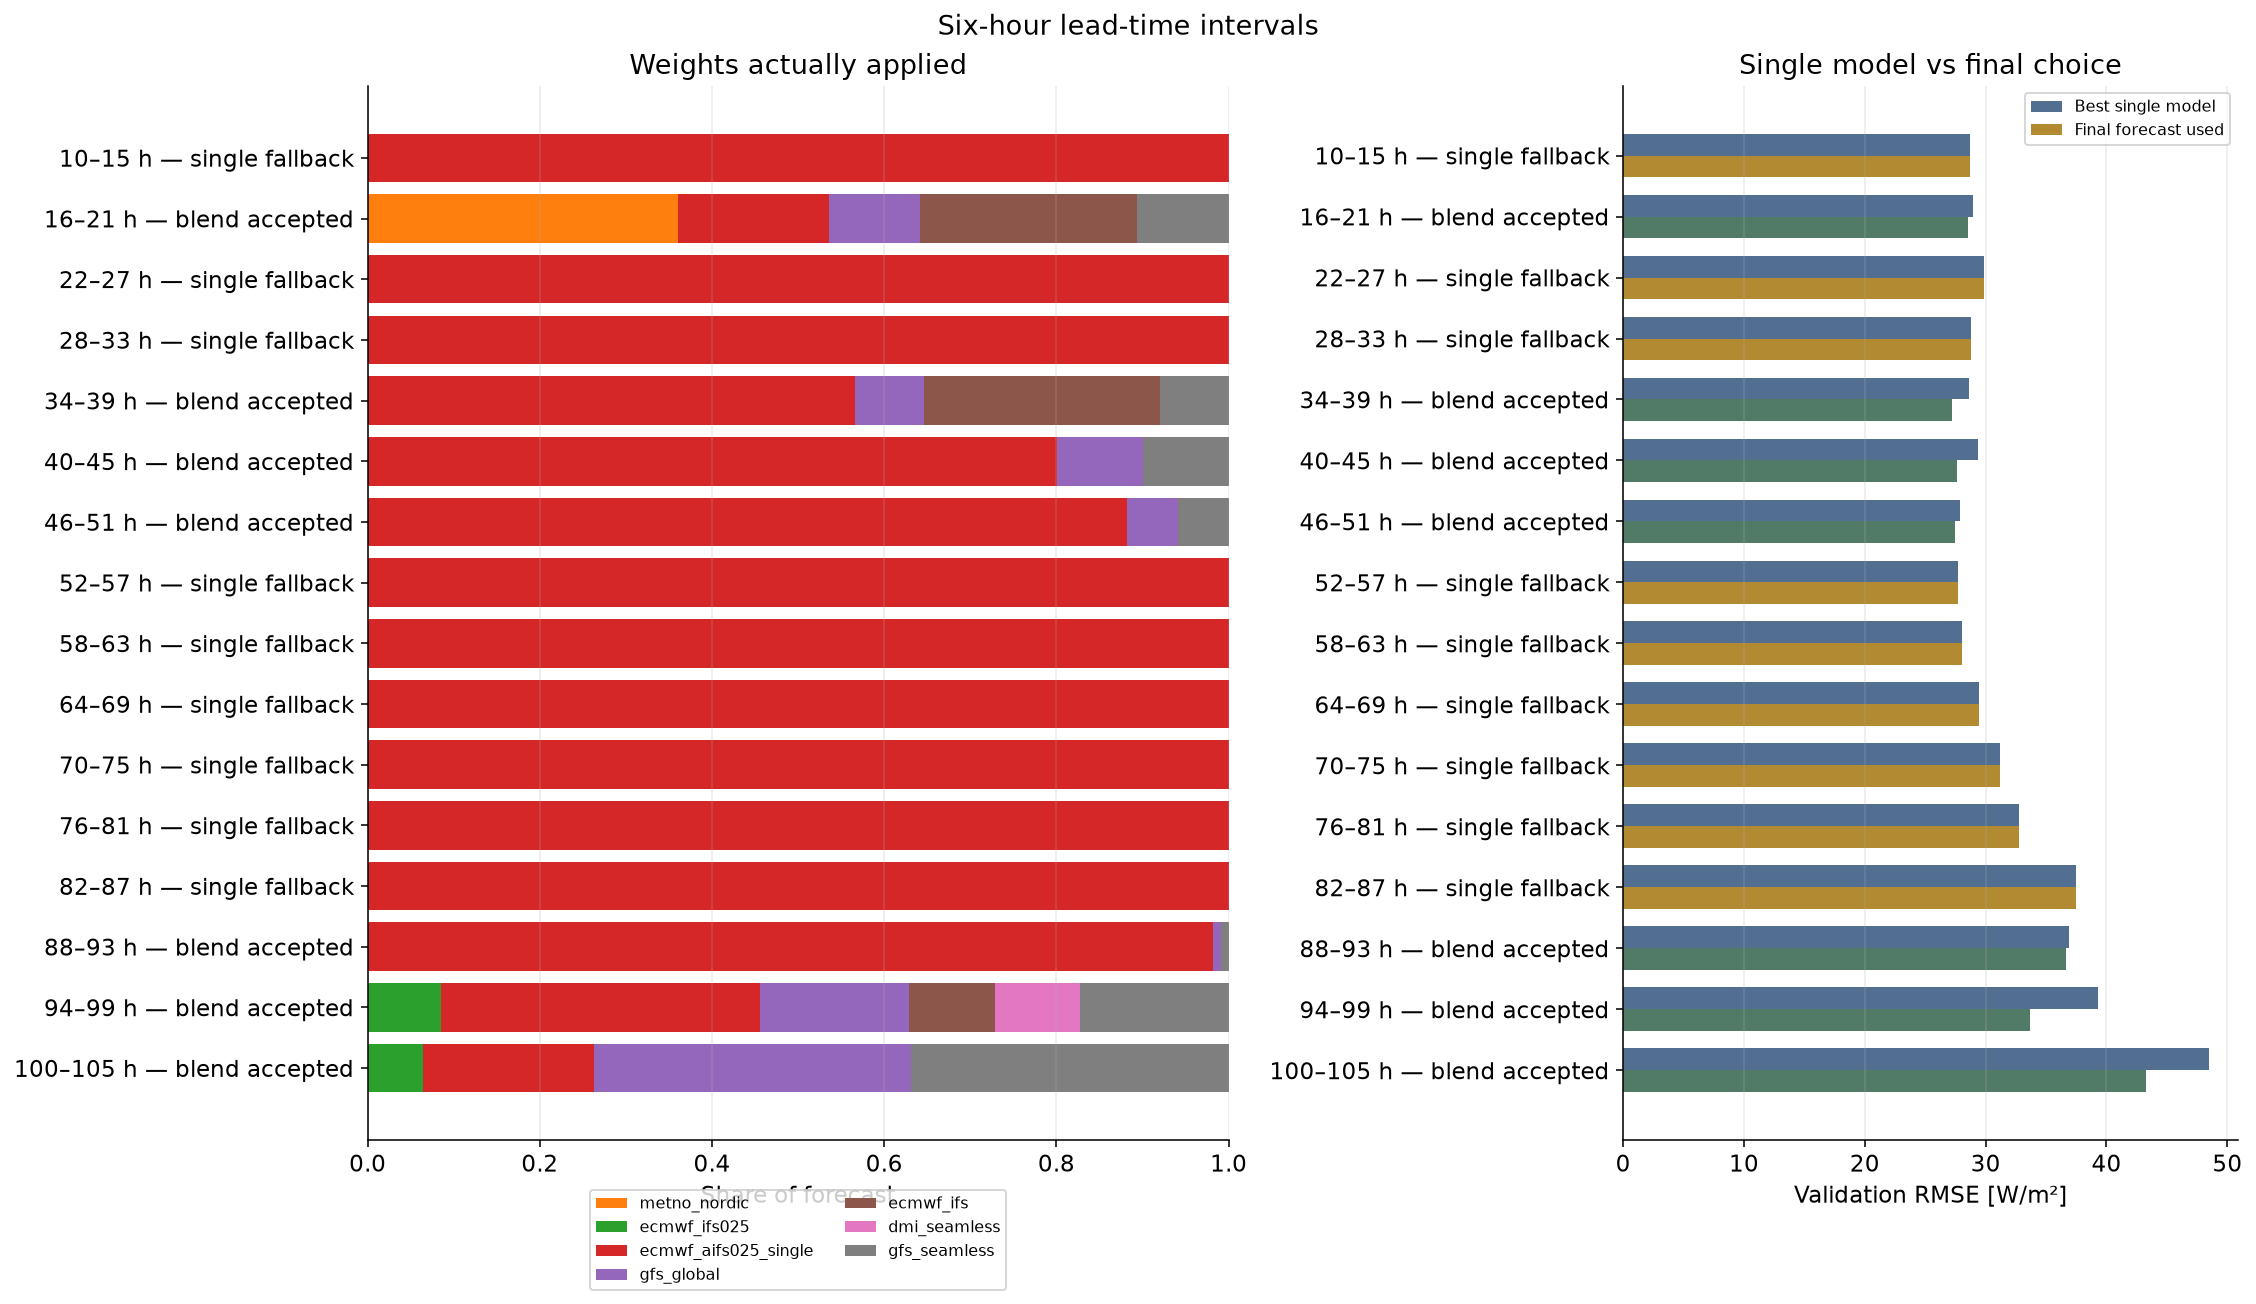

In [152]:
# Simple summary: weights actually used and validation RMSE comparison.
interval_labels = [f"{first}–{last} h" for first, last, _ in weight_schedule]
weight_rows = [weights for _, _, weights in weight_schedule]
weight_table = pd.DataFrame(weight_rows, index=interval_labels).fillna(0)
weight_table = weight_table.reindex(columns=list(forecast_unstacked), fill_value=0)

summary = blend_diagnostics.copy()
summary["validation_rmse_final"] = np.where(
    summary["accepted"],
    summary["validation_rmse_blend"],
    summary["validation_rmse_best_single"],
)
summary_labels = [
    f"{row.interval} — {'blend accepted' if row.accepted else 'single fallback'}"
    for row in summary.itertuples()
]

display(summary[[
    "interval",
    "status",
    "training_selected_single_model",
    "validation_rmse_best_single",
    "validation_rmse_blend",
    "validation_rmse_final",
    "n_validation",
]])

fig_height = max(7, 0.45 * len(interval_labels) + 2)
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, fig_height),
    gridspec_kw={"width_ratios": [1.4, 1]},
    constrained_layout=True,
)
y = np.arange(len(interval_labels))

# Each row sums to one and shows the model shares used in that interval.
ax = axes[0]
left = np.zeros(len(weight_table))
palette = plt.get_cmap("tab10")
for i, model in enumerate(weight_table.columns):
    values = weight_table[model].to_numpy()
    if np.any(values > 0.005):
        ax.barh(
            y,
            values,
            left=left,
            label=model,
            color=palette(i % 10),
        )
        left += values
ax.set_yticks(y)
ax.set_yticklabels(summary_labels)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Share of forecast")
ax.set_title("Weights actually applied")
ax.grid(axis="x", alpha=0.25)
ax.legend(bbox_to_anchor=(0.5, -0.04), loc="upper center", ncol=2, fontsize=8)

# Lower validation RMSE is better. On fallback intervals the two bars are equal.
ax = axes[1]
bar_height = 0.36
ax.barh(
    y - bar_height / 2,
    summary["validation_rmse_best_single"],
    height=bar_height,
    label="Best single model",
    color="#526F91",
)
ax.barh(
    y + bar_height / 2,
    summary["validation_rmse_final"],
    height=bar_height,
    label="Final forecast used",
    color=["#527B67" if accepted else "#B18A32" for accepted in summary["accepted"]],
)
ax.set_yticks(y)
ax.set_yticklabels(summary_labels)
ax.invert_yaxis()
ax.set_xlabel("Validation RMSE [W/m²]")
ax.set_title("Single model vs final choice")
ax.grid(axis="x", alpha=0.25)
ax.legend(fontsize=8)

fig.suptitle("Six-hour lead-time intervals", fontsize=14)
plt.show()


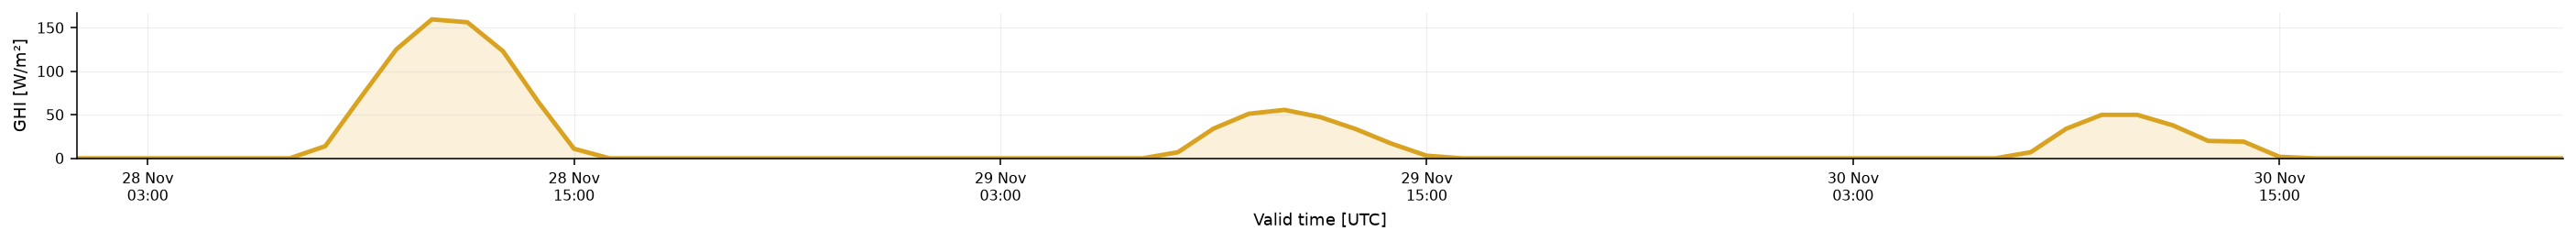

In [153]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Load submitted forecast
plot_data = pd.read_csv("Group1.csv")
plot_data["datetime"] = pd.to_datetime(plot_data["datetime"], utc=True)

fig, ax = plt.subplots(figsize=(20, 1.8))  # meget bred og lav

ax.plot(
    plot_data["datetime"],
    plot_data["ghi_forecast"],
    color="#D9A321",   # solar yellow
    linewidth=2.5,
)

ax.fill_between(
    plot_data["datetime"],
    plot_data["ghi_forecast"],
    0,
    color="#F2C66D",
    alpha=0.25,
)

# Akser og layout
ax.set_ylabel("GHI [W/m²]", fontsize=9)
ax.set_xlabel("Valid time [UTC]", fontsize=9)

ax.set_ylim(bottom=0)
ax.set_xlim(
    plot_data["datetime"].min(),
    plot_data["datetime"].max()
)

# Færre ticks så det kan læses i en lav figur
ax.xaxis.set_major_locator(mdates.HourLocator(interval=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
ax.tick_params(axis="both", labelsize=8)

# Rent layout til poster
ax.grid(alpha=0.2, linewidth=0.6)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout(pad=0.4)

# Gem til poster
fig.savefig(
    "final_blended_forecast_poster.svg",
    facecolor="white",
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()

In [154]:
# import numpy as np
# import pandas as pd
# from pathlib import Path

# # Perioden, der skal afleveres, i UTC.
# target_times = pd.date_range(
#     start="2026-11-28 01:00",
#     end="2026-11-30 23:00",
#     freq="h",
#     tz="UTC",
# )

# # Hent de seneste DTU-prognoser.
# # Målinger er ikke nødvendige for fremtidige forecasttider.
# empty_measurements = pd.DataFrame(
#     {"ghi_measured": pd.Series(dtype=float)},
#     index=pd.DatetimeIndex([], tz="UTC", name="valid_time"),
# )

# dtu_forecast_data = get_forecast_data(
#     empty_measurements,
#     station="dtu",
#     start="2026-11-26 00:00",
#     end="2026-11-27 13:00",
#     models=list(forecast_unstacked),
# )

# # Find alle modeller, der har en positiv vægt i mindst ét interval.
# required_models = sorted({
#     model
#     for _, _, weights in weight_schedule
#     for model, weight in weights.items()
#     if weight > 0
# })

# # Find issue times, som er tilgængelige for alle modeller med positiv vægt.
# issue_time_sets = []

# for model in required_models:
#     model_data = dtu_forecast_data[model]

#     if model_data.empty:
#         raise ValueError(f"Der blev ikke hentet DTU-data for modellen {model}.")

#     model_issue_times = set(
#         pd.to_datetime(model_data["issue_time"], utc=True)
#         .dropna()
#         .drop_duplicates()
#         .tolist()
#     )
#     issue_time_sets.append(model_issue_times)

# common_issue_times = set.intersection(*issue_time_sets)

# # Den valgte issue time skal placere alle måltimer inden for vægtplanens
# # lead-time-intervaller.
# min_lead = min(first for first, _, _ in weight_schedule)
# max_lead = max(last for _, last, _ in weight_schedule)

# earliest_issue = target_times[-1] - pd.Timedelta(hours=max_lead)
# latest_issue = target_times[0] - pd.Timedelta(hours=min_lead)

# candidate_issue_times = sorted(
#     [
#         issue_time
#         for issue_time in common_issue_times
#         if earliest_issue <= issue_time <= latest_issue
#     ],
#     reverse=True,
# )

# selected_issue_time = None
# selected_values = None

# # Prøv den nyeste fælles issue time først.
# for issue_time in candidate_issue_times:
#     leads_by_time = {
#         valid_time: int(
#             round((valid_time - issue_time) / pd.Timedelta(hours=1))
#         )
#         for valid_time in target_times
#     }

#     # Kontrollér, at vægtplanen indeholder alle lead times.
#     all_leads_supported = all(
#         any(first <= lead <= last for first, last, _ in weight_schedule)
#         for lead in leads_by_time.values()
#     )

#     if not all_leads_supported:
#         continue

#     forecasts_for_issue = {}

#     for model in required_models:
#         model_data = dtu_forecast_data[model].copy()
#         model_data["issue_time"] = pd.to_datetime(
#             model_data["issue_time"],
#             utc=True,
#         )

#         issue_data = model_data.loc[
#             model_data["issue_time"] == issue_time
#         ]

#         forecasts_for_issue[model] = issue_data.pivot_table(
#             index="valid_time",
#             columns="lead_time_h",
#             values="ghi_forecast",
#             aggfunc="first",
#         )

#     # Anvend de validerede vægte på DTU-prognoser fra samme issue time.
#     blended_issue = our_blend_by_lead_time(
#         forecasts_for_issue,
#         weight_schedule,
#     )

#     values = []

#     for valid_time, lead in leads_by_time.items():
#         if (
#             valid_time not in blended_issue.index
#             or lead not in blended_issue.columns
#         ):
#             values.append(np.nan)
#         else:
#             values.append(blended_issue.at[valid_time, lead])

#     values = pd.Series(values, index=target_times, dtype=float)

#     # Brug kun denne issue time, hvis alle afleveringsværdier findes.
#     if values.notna().all():
#         selected_issue_time = issue_time
#         selected_values = values
#         break

# if selected_issue_time is None:
#     raise ValueError(
#         "Ingen fælles DTU-prognosekørsel dækker alle timer i perioden med "
#         "de validerede vægte. Tjek, om nyere DTU-prognosefiler er tilgængelige, "
#         "og kør cellen igen."
#     )

# # Lav CSV-filen med dato/tid i første kolonne.
# submission = pd.DataFrame({
#     "datetime": target_times.strftime("%Y-%m-%d %H:%M+00:00"),
#     "ghi_forecast": selected_values.to_numpy(),
# })

# assert len(submission) == 71
# assert submission["ghi_forecast"].notna().all()

# # Erstat X med jeres gruppenummer, fx "3" for Group3.csv.
# GROUP_NUMBER = "1"
# output_file = Path(f"Group{GROUP_NUMBER}.csv")

# submission.to_csv(output_file, index=False)

# print(f"Valgt DTU issue time: {selected_issue_time}")
# print(f"Antal forecasttimer: {len(submission)}")
# print(f"Fil gemt som: {output_file.resolve()}")
# display(submission.head())
# display(submission.tail())

In [155]:
# import pandas as pd
# import matplotlib.pyplot as plt

# plot_data = submission.copy()
# plot_data["datetime"] = pd.to_datetime(plot_data["datetime"], utc=True)
# plot_data["ghi_forecast"] = pd.to_numeric(plot_data["ghi_forecast"])

# fig, ax = plt.subplots(figsize=(13, 5))

# ax.plot(
#     plot_data["datetime"],
#     plot_data["ghi_forecast"],
#     color="#2878B5",
#     linewidth=1.8,
#     marker="o",
#     markersize=3,
#     label="Blended DTU forecast",
# )

# ax.set_title("Submitted blended GHI forecast for DTU")
# ax.set_xlabel("Valid time [UTC]")
# ax.set_ylabel("Forecast GHI [W/m²]")
# ax.grid(alpha=0.25)
# ax.legend()
# fig.autofmt_xdate()
# plt.tight_layout()
# plt.show()

## Final results: separate 60/20/20 backtest

Training ends before:   2026-11-19 15:00:00+00:00
Validation period:     2026-11-19 15:00:00+00:00 to before 2026-11-23 13:00:00+00:00
Test period starts:    2026-11-23 13:00:00+00:00
Test period ends:      2026-11-27 14:00:00+00:00


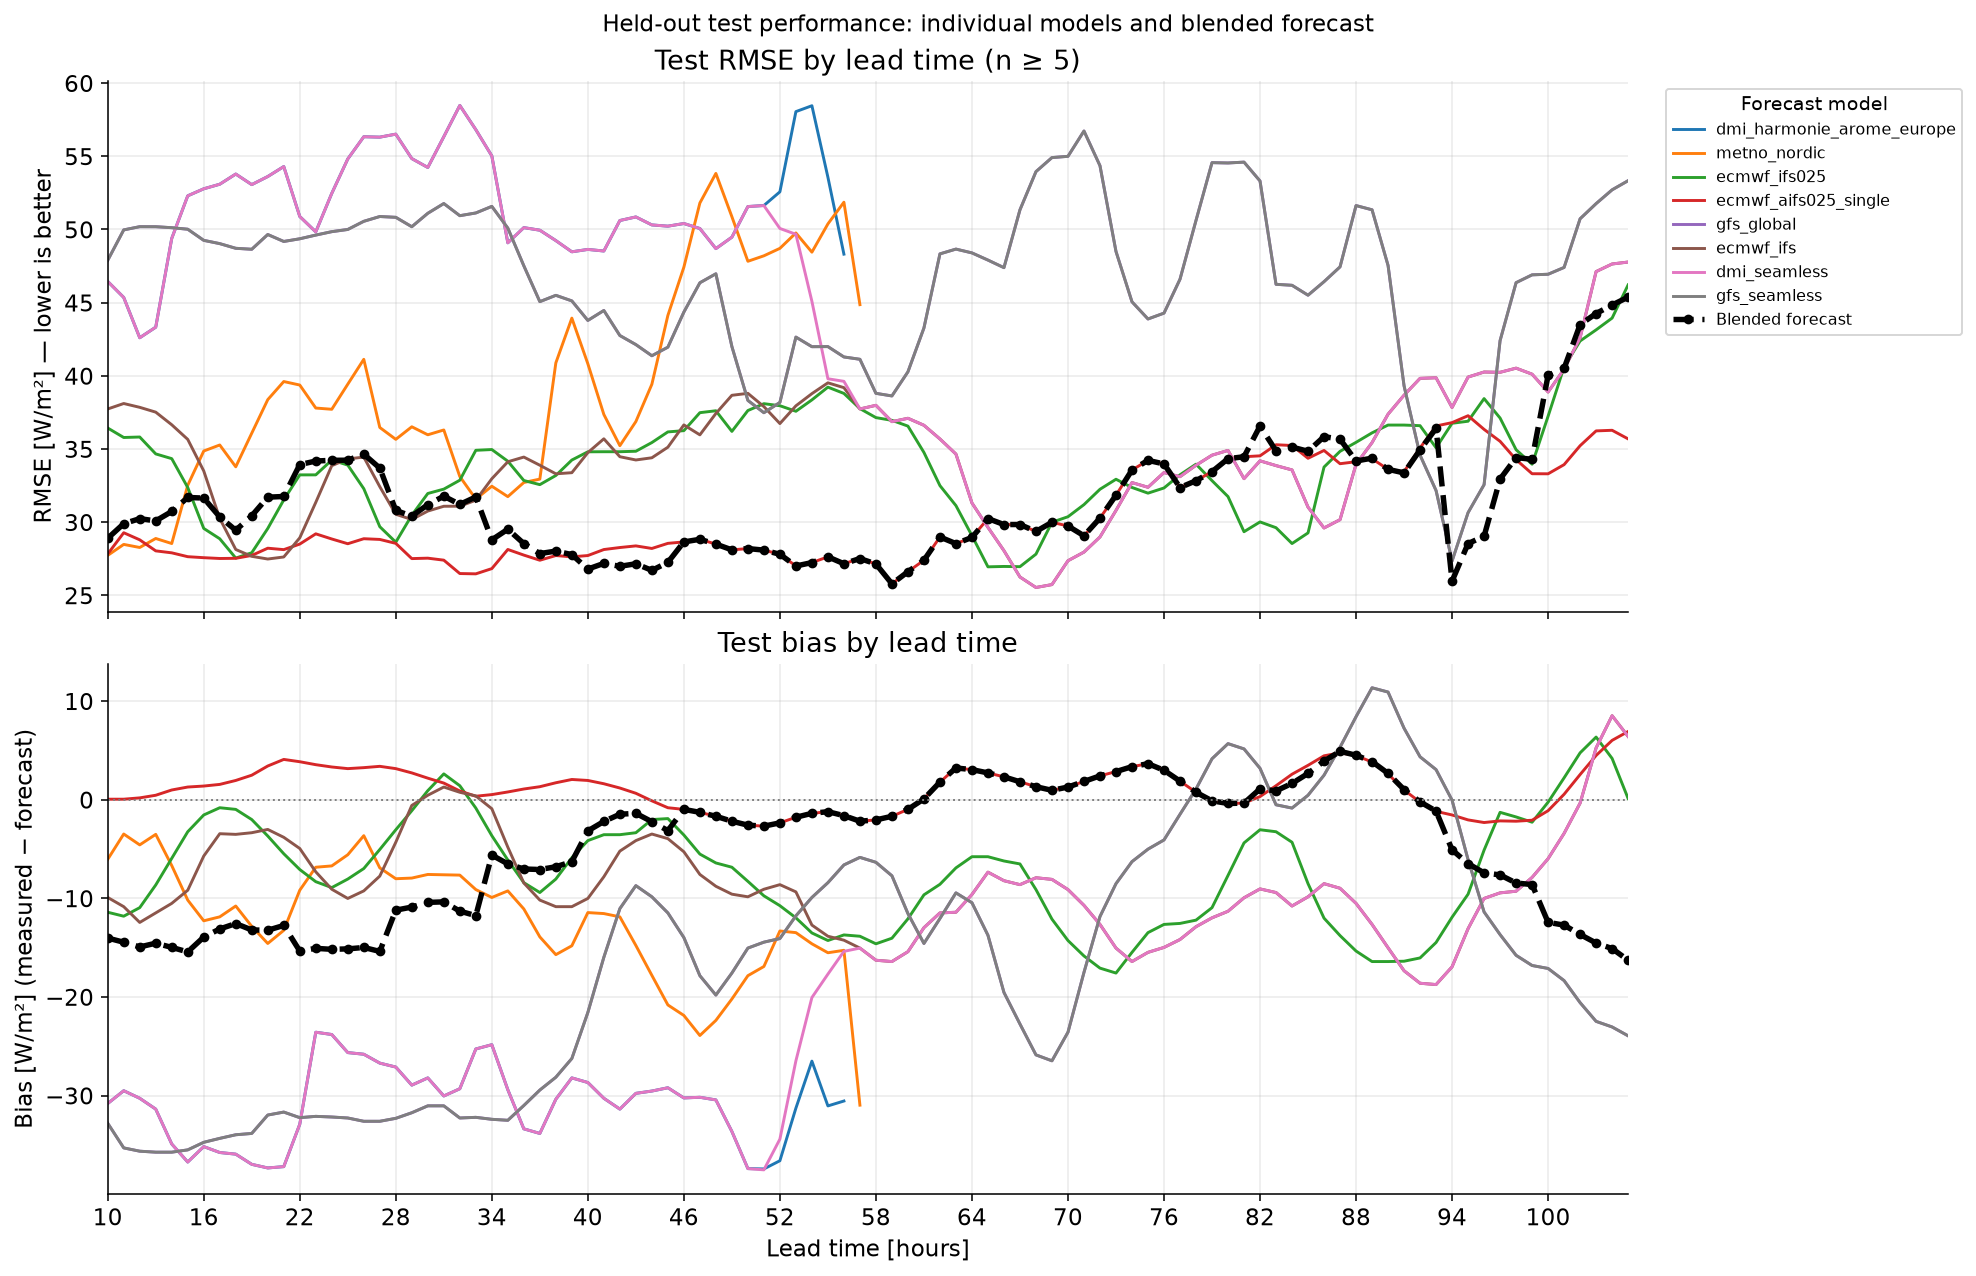

In [156]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Brug samme lead-time-intervaller som i afleveringsmodellen.
backtest_intervals = [
    (first, first + 5)
    for first in range(10, 106, 6)
]

# Find gyldige tidspunkter med både måling og mindst én forecast.
backtest_measured = (
    hourly_dmi["ghi_measured"]
    .replace([np.inf, -np.inf], np.nan)
)

backtest_forecast_times = pd.Index([])
for forecast in forecast_unstacked.values():
    backtest_forecast_times = backtest_forecast_times.union(forecast.index)

backtest_matched_times = (
    backtest_measured.index[backtest_measured.notna()]
    .intersection(backtest_forecast_times)
    .sort_values()
)

if len(backtest_matched_times) < 10:
    raise ValueError("For få matched tidspunkter til en train/validation/test-split.")

# Kronologisk split: 60 % træning, 20 % validation, 20 % test.
train_end_position = int(len(backtest_matched_times) * 0.60)
test_start_position = int(len(backtest_matched_times) * 0.80)

backtest_validation_start = backtest_matched_times[train_end_position]
backtest_test_start = backtest_matched_times[test_start_position]

backtest_train = {
    model: forecast.loc[forecast.index < backtest_validation_start].copy()
    for model, forecast in forecast_unstacked.items()
}

backtest_validation = {
    model: forecast.loc[
        (forecast.index >= backtest_validation_start)
        & (forecast.index < backtest_test_start)
    ].copy()
    for model, forecast in forecast_unstacked.items()
}

backtest_test = {
    model: forecast.loc[forecast.index >= backtest_test_start].copy()
    for model, forecast in forecast_unstacked.items()
}

print(f"Training ends before:   {backtest_validation_start}")
print(f"Validation period:     {backtest_validation_start} to before {backtest_test_start}")
print(f"Test period starts:    {backtest_test_start}")
print(f"Test period ends:      {backtest_matched_times[-1]}")

# Vælg vægte på træningsdata, og brug validation til at acceptere/forkaste blendet.
backtest_weight_schedule, backtest_diagnostics, _ = (
    fit_blend_weights_by_lead_time(
        backtest_train,
        backtest_validation,
        hourly_dmi,
        intervals=backtest_intervals,
        min_train_samples=30,
        min_validation_samples=10,
    )
)

# Først nu anvendes den valgte vægtplan på det urørte testdatasæt.
backtest_blend = our_blend_by_lead_time(
    backtest_test,
    backtest_weight_schedule,
)

test_forecasts = dict(backtest_test)
test_forecasts["Blended forecast"] = backtest_blend

# Beregn RMSE og bias for hver model og lead time på testdata.
test_score_rows = []

for model, forecast in test_forecasts.items():
    for lead_column in forecast.columns:
        try:
            lead_time = int(round(float(lead_column)))
        except (TypeError, ValueError):
            continue

        if not 10 <= lead_time <= 105:
            continue

        prediction = forecast[lead_column].replace(
            [np.inf, -np.inf], np.nan
        )
        observation = backtest_measured.reindex(prediction.index)

        pairs = pd.concat(
            [
                prediction.rename("forecast"),
                observation.rename("measured"),
            ],
            axis=1,
        ).dropna()

        if pairs.empty:
            continue

        error = pairs["measured"] - pairs["forecast"]

        test_score_rows.append({
            "model": model,
            "lead_time_h": lead_time,
            "n": len(pairs),
            "rmse": np.sqrt(np.mean(error**2)),
            "bias": error.mean(),
        })

test_scores = pd.DataFrame(test_score_rows)

if test_scores.empty:
    raise ValueError("Ingen matched forecast- og måledata i testperioden.")

# Skjul lead times med få observationer.
min_test_samples = 5
test_scores.loc[
    test_scores["n"] < min_test_samples,
    ["rmse", "bias"],
] = np.nan

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 9),
    sharex=True,
    constrained_layout=True,
)

colors = plt.get_cmap("tab10").colors

for i, model in enumerate(test_forecasts):
    model_scores = (
        test_scores.loc[test_scores["model"] == model]
        .sort_values("lead_time_h")
    )

    if model_scores.empty:
        continue

    is_blend = model == "Blended forecast"
    color = "black" if is_blend else colors[i % len(colors)]
    linewidth = 2.8 if is_blend else 1.5
    linestyle = "--" if is_blend else "-"

    axes[0].plot(
        model_scores["lead_time_h"],
        model_scores["rmse"],
        color=color,
        linewidth=linewidth,
        linestyle=linestyle,
        marker="o" if is_blend else None,
        markersize=4,
        label=model,
    )

    axes[1].plot(
        model_scores["lead_time_h"],
        model_scores["bias"],
        color=color,
        linewidth=linewidth,
        linestyle=linestyle,
        marker="o" if is_blend else None,
        markersize=4,
        label=model,
    )

axes[0].set_title(
    f"Test RMSE by lead time (n ≥ {min_test_samples})"
)
axes[0].set_ylabel("RMSE [W/m²] — lower is better")
axes[0].grid(alpha=0.25)
axes[0].legend(
    title="Forecast model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

axes[1].axhline(0, color="grey", linewidth=1, linestyle=":")
axes[1].set_title("Test bias by lead time")
axes[1].set_ylabel("Bias [W/m²] (measured − forecast)")
axes[1].set_xlabel("Lead time [hours]")
axes[1].set_xlim(10, 105)
axes[1].set_xticks(range(10, 106, 6))
axes[1].grid(alpha=0.25)

fig.suptitle(
    "Held-out test performance: individual models and blended forecast"
)
plt.show()

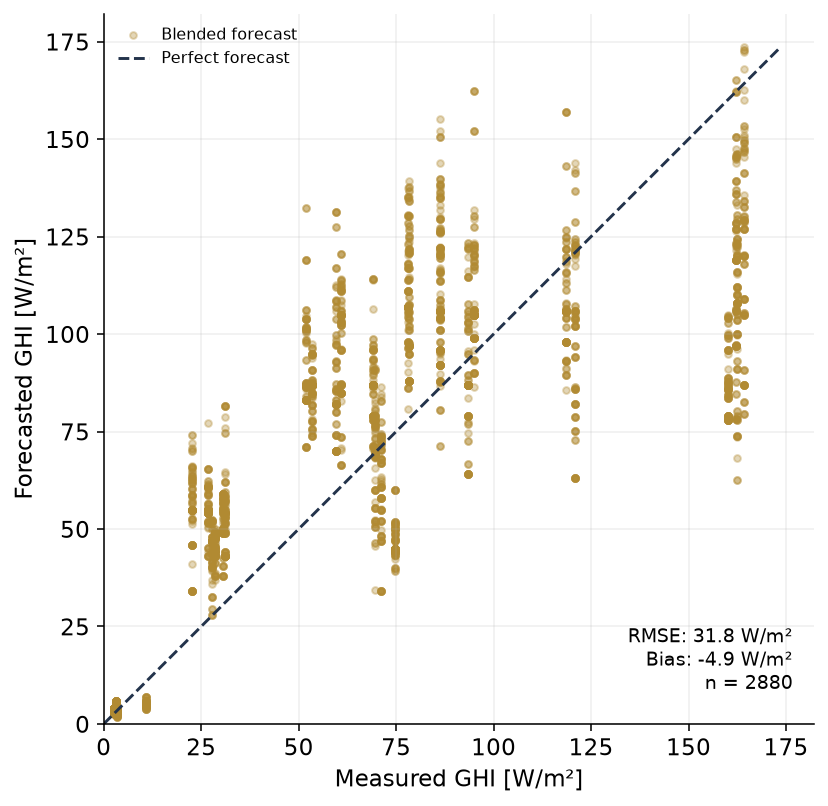

In [157]:
# Match blended forecast with measured GHI
scatter_rows = []

for lead in backtest_blend.columns:

    if not 10 <= float(lead) <= 105:
        continue

    prediction = backtest_blend[lead]
    observation = hourly_dmi["ghi_measured"].reindex(prediction.index)

    pairs = pd.concat(
        [
            observation.rename("measured"),
            prediction.rename("forecast"),
        ],
        axis=1,
    ).replace([np.inf, -np.inf], np.nan).dropna()

    scatter_rows.append(pairs)

scatter_data = pd.concat(scatter_rows, ignore_index=True)

# Calculate RMSE and bias
error = scatter_data["measured"] - scatter_data["forecast"]

rmse = np.sqrt(np.mean(error**2))
bias = error.mean()

# Scatterplot
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    scatter_data["measured"],
    scatter_data["forecast"],
    color="#B18A32",
    alpha=0.35,
    s=12,
    label="Blended forecast",
)

# Perfect forecast (1:1 line)
limit = scatter_data[["measured", "forecast"]].max().max()

ax.plot(
    [0, limit],
    [0, limit],
    color="#23334B",
    linestyle="--",
    linewidth=1.5,
    label="Perfect forecast",
)

# Performance metrics
ax.text(
    0.97, 0.04,
    f"RMSE: {rmse:.1f} W/m²\n"
    f"Bias: {bias:.1f} W/m²\n"
    f"n = {len(scatter_data)}",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
)

ax.set_xlabel("Measured GHI [W/m²]")
ax.set_ylabel("Forecasted GHI [W/m²]")

ax.set_xlim(0, limit * 1.05)
ax.set_ylim(0, limit * 1.05)
ax.set_aspect("equal")

ax.legend(loc="upper left", frameon=False)
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()

fig.savefig(
    "Blended_vs_measured_GHI.svg",
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

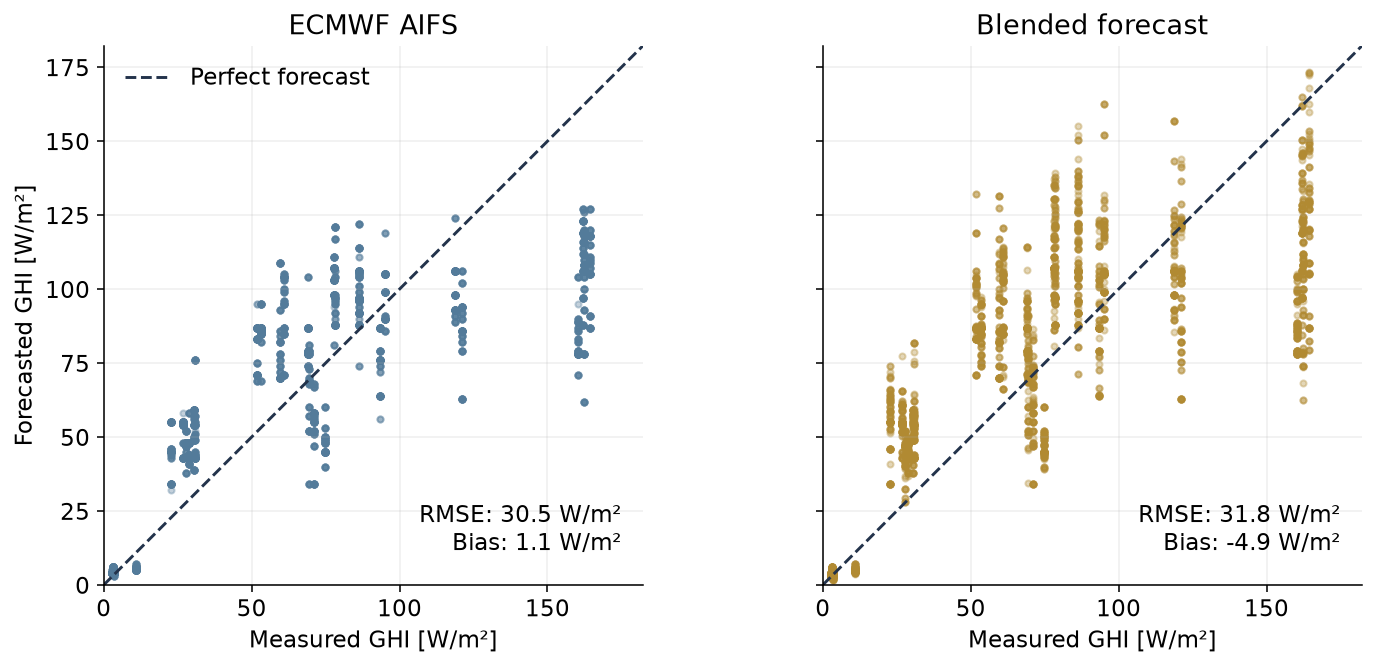

Matched forecast-observation pairs: 2880


In [158]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

baseline_model = "ecmwf_aifs025_single"

baseline = backtest_test[baseline_model].copy()
blend = backtest_blend.copy()

# Ensure consistent lead-time columns
baseline.columns = baseline.columns.astype(float).round().astype(int)
blend.columns = blend.columns.astype(float).round().astype(int)

# Match observations across both models and all common lead times
scatter_rows = []

common_leads = baseline.columns.intersection(blend.columns)

for lead in common_leads:

    if not 10 <= lead <= 105:
        continue

    pairs = pd.concat(
        [
            hourly_dmi["ghi_measured"].rename("Measured"),
            baseline[lead].rename("AIFS"),
            blend[lead].rename("Blend"),
        ],
        axis=1,
    ).replace([np.inf, -np.inf], np.nan).dropna()

    scatter_rows.append(pairs)

scatter_data = pd.concat(scatter_rows, ignore_index=True)

# Identical axis limits
lower = min(0, scatter_data.min().min())
upper = scatter_data.max().max() * 1.05

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.15, 5),
    sharex=True,
    sharey=True,
)

models = [
    ("AIFS", "ECMWF AIFS", "#537B9A"),
    ("Blend", "Blended forecast", "#B18A32"),
]

for ax, (column, title, color) in zip(axes, models):

    error = scatter_data["Measured"] - scatter_data[column]

    rmse = np.sqrt(np.mean(error**2))
    bias = error.mean()

    ax.scatter(
        scatter_data["Measured"],
        scatter_data[column],
        color=color,
        alpha=0.35,
        s=10,
    )

    # Perfect forecast
    ax.plot(
        [lower, upper],
        [lower, upper],
        color="#23334B",
        linestyle="--",
        linewidth=1.5,
        label="Perfect forecast",
    )

    # Performance metrics
    ax.text(
        0.96, 0.05,
        f"RMSE: {rmse:.1f} W/m²\n"
        f"Bias: {bias:.1f} W/m²",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=12,
    )

    ax.set_title(title, fontsize=14,)
    ax.set_xlabel("Measured GHI [W/m²]")
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Forecasted GHI [W/m²]")
axes[0].legend(loc="upper left", frameon=False, fontsize=12)

# Save both plots as one figure
fig.savefig("AIFS_vs_Blended_scatter.svg", bbox_inches="tight", facecolor="white",)
plt.show()

print(f"Matched forecast-observation pairs: {len(scatter_data)}")

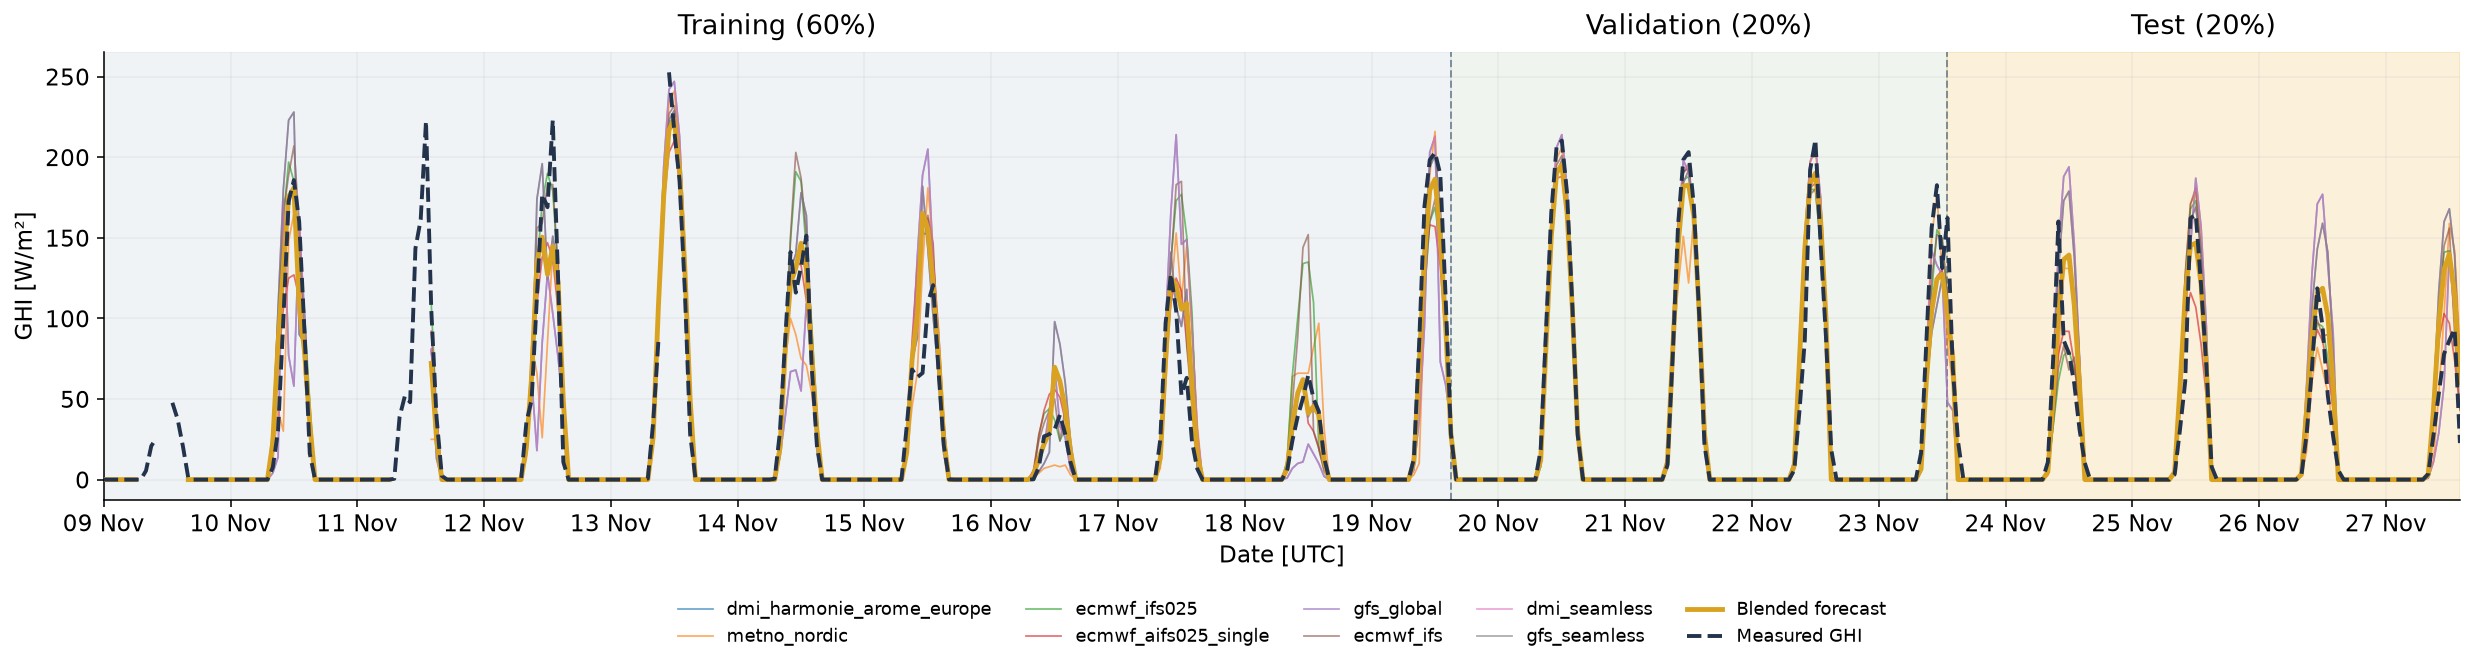

In [161]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pvlib

# Plot settings
plot_lead = 24

start = pd.Timestamp("2026-11-09", tz="UTC")
end = backtest_matched_times[-1]

hours = pd.date_range(start, end, freq="h")

# Apply backtest weights to the full historical period
historical_blend = our_blend_by_lead_time(
    forecast_unstacked,
    backtest_weight_schedule,
)

# Collect measured GHI
plot_df = pd.DataFrame(index=hours)

plot_df["Measured GHI"] = (
    hourly_dmi["ghi_measured"].reindex(hours)
)

# Collect all individual forecast models
for model, forecast in forecast_unstacked.items():

    forecast = forecast.copy()
    forecast.columns = forecast.columns.astype(float).round().astype(int)

    if plot_lead in forecast.columns:
        plot_df[model] = forecast[plot_lead].reindex(hours)

# Add blended forecast
historical_blend.columns = (
    historical_blend.columns.astype(float).round().astype(int)
)

plot_df["Blended forecast"] = (
    historical_blend[plot_lead].reindex(hours)
)

plot_df = plot_df.replace([np.inf, -np.inf], np.nan)

# Restore missing nighttime values for visualization
solpos_plot = pvlib.solarposition.get_solarposition(
    hours,
    latitude=56.93,
    longitude=8.6412,
)

nighttime = solpos_plot["apparent_elevation"] <= 0

plot_df.loc[nighttime] = plot_df.loc[nighttime].fillna(0)

# Create figure
fig, ax = plt.subplots(figsize=(18, 5))

# Background colors for the chronological data split
ax.axvspan(
    start,
    backtest_validation_start,
    color="#DCE5ED",
    alpha=0.45,
    zorder=0,
)

ax.axvspan(
    backtest_validation_start,
    backtest_test_start,
    color="#DCE8DC",
    alpha=0.45,
    zorder=0,
)

ax.axvspan(
    backtest_test_start,
    end,
    color="#F2C66D",
    alpha=0.25,
    zorder=0,
)

# Vertical lines marking the split
for boundary in [
    backtest_validation_start,
    backtest_test_start,
]:
    ax.axvline(
        boundary,
        color="#52657B",
        linestyle="--",
        linewidth=1,
        alpha=0.7,
    )

# Plot individual models
colors = plt.get_cmap("tab10").colors

for i, model in enumerate(forecast_unstacked):

    if model not in plot_df.columns:
        continue

    ax.plot(
        plot_df.index,
        plot_df[model],
        color=colors[i % len(colors)],
        linewidth=0.9,
        alpha=0.65,
        label=model,
    )

# Plot blended forecast
ax.plot(
    plot_df.index,
    plot_df["Blended forecast"],
    color="#D9A321",
    linewidth=2.5,
    label="Blended forecast",
    zorder=9,
)

# Plot measured GHI
ax.plot(
    plot_df.index,
    plot_df["Measured GHI"],
    color="#23334B",
    linestyle="--",
    linewidth=2,
    label="Measured GHI",
    zorder=10,
)

# Labels above each data split
periods = [
    (start, backtest_validation_start, "Training (60%)"),
    (
        backtest_validation_start,
        backtest_test_start,
        "Validation (20%)"
    ),
    (backtest_test_start, end, "Test (20%)"),
]

for left, right, label in periods:

    midpoint = left + (right - left) / 2

    ax.text(
        midpoint,
        1.025,
        label,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=14,
    )

# Formatting
ax.set_ylabel("GHI [W/m²]", fontsize=12)
ax.set_xlabel("Date [UTC]", fontsize=12)

ax.set_xlim(start, end)

ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d Nov"))

ax.grid(alpha=0.15)
ax.spines[["top", "right"]].set_visible(False)

# Shared legend below the plot
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.19),
    ncol=5,
    fontsize=9,
    frameon=False,
)

fig.subplots_adjust(
    left=0.055,
    right=0.99,
    bottom=0.26,
    top=0.90,
)

# Save figure for poster
fig.savefig(
    "All_models_GHI_train_validation_test.svg",
    facecolor="white",
)


plt.show()

In [162]:
# Check forecast availability by date
forecast_availability = (
    plot_df.loc[:, list(forecast_unstacked)]
    .notna()
    .where(~nighttime)
    .resample("D")
    .sum()
)

display(forecast_availability)

,dmi_harmonie_arome_europe,metno_nordic,ecmwf_ifs025,ecmwf_aifs025_single,gfs_global,ecmwf_ifs,dmi_seamless,gfs_seamless
2026-11-09 00:00:00+00:00,0,0,0,0,0,0,0,0
2026-11-10 00:00:00+00:00,9,9,9,9,9,9,9,9
2026-11-11 00:00:00+00:00,2,2,2,2,2,2,2,2
2026-11-12 00:00:00+00:00,8,8,8,8,8,8,8,8
2026-11-13 00:00:00+00:00,8,8,8,8,8,8,8,8
2026-11-14 00:00:00+00:00,8,8,8,8,8,8,8,8
2026-11-15 00:00:00+00:00,8,8,8,8,8,8,8,8
2026-11-16 00:00:00+00:00,8,8,8,8,8,8,8,8
2026-11-17 00:00:00+00:00,8,8,8,8,8,8,8,8
2026-11-18 00:00:00+00:00,8,8,8,8,8,8,8,8
